# IndustrialGuard — Notebook 1 : Étude des données HAI 23.05
### Phase 1 · Data Engineering — compréhension, exploration (EDA), qualité, préparation

| | |
|---|---|
| **Projet** | IndustrialGuard — plateforme MLOps de détection d'anomalies industrielles |
| **Objectif du notebook** | Comprendre, auditer et préparer le dataset HAI 23.05 de façon **reproductible** et **justifiée** |
| **Entrées** | CSV bruts HAI 23.05 (Kaggle) |
| **Sorties** | jeux `train / val_normal / val / test` (parquet), scaler, liste de variables, statistiques de référence (drift), figures, data card |
| **Principe directeur** | *Aucune décision de prétraitement sans preuve issue de l'exploration.* |

---
### Plan
1. Contexte métier et glossaire
2. Configuration et reproductibilité
3. Inventaire des données et rôle de chaque fichier
4. Chargement et schéma
5. Dictionnaire des variables (tags)
6. EDA univariée
7. EDA temporelle
8. EDA multivariée (corrélations, PCA)
9. Analyse des attaques (labels)
10. Dérive naturelle entre jeux (train vs test)
11. Qualité des données
12. Décisions de prétraitement
13. Nettoyage, découpage temporel, normalisation
14. Validation du prétraitement
15. Sauvegarde et traçabilité (data card, DVC)
16. Synthèse et implications pour la Phase 2

> **Comment lire ce notebook.** Chaque analyse suit le même schéma : **Pourquoi** (objectif) → **Code** → **Résultat** → **💡 Interprétation** (générée à partir des chiffres réels) → **Décision**.

## 1. Contexte métier et glossaire

### 1.1 Le banc d'essai HAI
HAI (*HIL-based Augmented ICS*) a été collecté sur un banc d'essai de système de contrôle industriel (ICS) **réel**, couplé à une simulation **Hardware-In-the-Loop (HIL)** de production d'énergie (centrale à turbine à vapeur et hydroélectricité à réserve pompée). Quatre processus sont interconnectés :

| Processus | Préfixe des tags | Rôle |
|---|---|---|
| **P1 — Chaudière (Boiler)** | `P1_` | transfert thermique eau/eau, pression et température modérées (DCS Emerson Ovation) |
| **P2 — Turbine** | `P2_` | banc rotor simulant une machine tournante (DCS GE Mark VIe) |
| **P3 — Traitement d'eau** | `P3_` | pompage vers/depuis des réservoirs (PLC Siemens S7-300) |
| **P4 — Simulation HIL** | `P4_` | modèle virtuel de centrale qui synchronise P1, P2, P3 (dSPACE SCALEXIO) |

Le couplage via HIL rend les variables **fortement corrélées entre processus** : une attaque sur un actionneur se propage sur plusieurs capteurs. C'est à la fois une difficulté et une opportunité pour la détection multivariée (F9) et l'explicabilité (F8).

### 1.2 Structure du dataset (HAI 23.05)
- **86 variables** (HAI) échantillonnées à **1 Hz** (HAIEnd, 225 variables, n'est **pas** utilisé ici).
- Fichiers **train** : fonctionnement **normal uniquement** (≈ 249 h au total).
- Fichiers **test** : fonctionnement normal **entrecoupé d'attaques** (52 attaques sur ≈ 79 h), avec des **labels** 0/1 par seconde.
- Chaque fichier est continu dans le temps (les trous éventuels sont à vérifier — section 7 et 11).

### 1.3 Pourquoi cette structure impose une méthodologie
| Contrainte du dataset | Conséquence de conception |
|---|---|
| Train 100 % normal | apprentissage **non supervisé / semi-supervisé** (Isolation Forest, AE, LSTM-AE) |
| Labels seulement dans le test | le **seuil** et l'évaluation doivent se faire sur les fichiers test (split val/test) |
| Données séquentielles | découpage **temporel**, jamais aléatoire (pas de fuite) |
| Classes très déséquilibrées | accuracy interdite ; métriques **temporelles** (Precision, Recall, F1, **eTaPR**) |

### 1.4 Glossaire
**ICS** système de contrôle industriel · **PLC** automate programmable · **DCS** système de contrôle distribué · **HIL** simulation matériel-dans-la-boucle · **OPC-UA** protocole de collecte industriel · **Tag** nom d'une variable (capteur, actionneur, consigne) · **Consigne (setpoint)** valeur cible d'une boucle de régulation · **Drift** changement de distribution des données · **TaPR / eTaPR** métriques précision/rappel *tenant compte du temps* pour les séries temporelles (utilisées par la communauté HAI).

### 1.5 Vue d'ensemble de la chaîne de données (ce notebook)
Le diagramme ci-dessous est généré par le code (section 2) et sauvegardé dans `reports/figures/`.

## 2. Configuration et reproductibilité

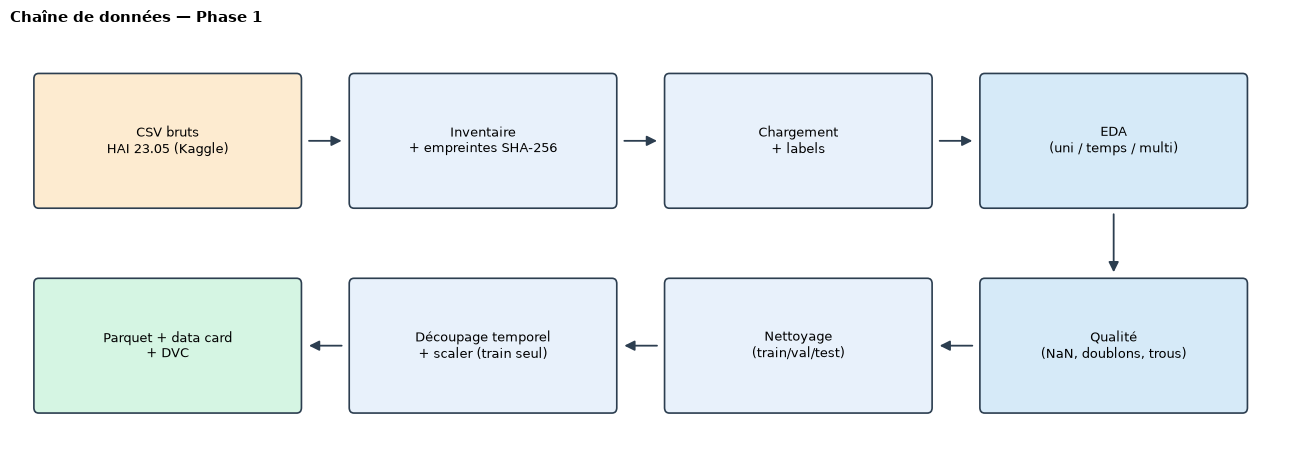

,valeur
python,3.14.7
pandas,3.0.6
numpy,2.5.3
scikit-learn,1.9.1
scipy,1.18.1
seed,42
date_exécution,2026-11-12T15:02:10
git_commit,non versionné


In [3]:
from pathlib import Path
import json, re, hashlib, platform, subprocess, warnings, sys, datetime as dtm
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Patch
import joblib, scipy, sklearn
from scipy import stats
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
warnings.filterwarnings("ignore")

# ---------- Chemins ----------
ROOT = Path.cwd() if (Path.cwd() / "params.yaml").exists() else Path.cwd().parent

sys.path.insert(0, str(ROOT))
try:
    from src.data.io import find_hai_files, load_hai_csv, sensor_columns as sensor_cols
    from src.data.catalog import segments, parse_summary, crosscheck
    from src.data.prep import clean_file, apply_embargo, split_frames, prepare_protocol, save_prepared
except ImportError as e:
    raise ImportError("Lance Jupyter depuis le dossier du projet (celui qui contient params.yaml et src/). Détail : " + str(e))
DATA_ROOT = ROOT / "data" / "raw"          # <<< MODIFIE si ton dossier Kaggle est ailleurs (recherche récursive)
OUT_DIR   = ROOT / "data" / "processed";  OUT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR = ROOT / "reports";            REPORT_DIR.mkdir(exist_ok=True)
FIG_DIR = REPORT_DIR / "figures";         FIG_DIR.mkdir(exist_ok=True)

# ---------- Paramètres (tous justifiés en section 12) ----------
VERSION_TAG = "23.05"
SEED = 42
FREQ_S = 1                 # fréquence nominale : 1 Hz
MAX_FFILL_S = 5            # comblement des petits trous seulement
TRAIN_CLIP_SIGMA = 10      # winsorisation du TRAIN uniquement
ROBUST_Z = 8.0             # seuil de valeur aberrante (z robuste MAD)
CORR_THRESHOLD = 0.95      # seuil de redondance entre variables
DROP_CORRELATED = False    # on documente la redondance mais on ne supprime pas (voir section 12)
KS_THRESHOLD = 0.15        # écart de distribution jugé notable (statistique de Kolmogorov-Smirnov)
SAMPLE_N = 100_000         # taille des sous-échantillons pour les graphiques coûteux
EXCLUDE_COLUMNS = []       # exclusions manuelles éventuelles
STRICT_OFFICIAL_CHECKS = True   # contrôles de durée/nombre d'attaques vs doc officielle HAI (False UNIQUEMENT pour un test à blanc sur données de démo)
LEVEL_Z = 4.0              # attaque : variable « affectée » si |changement de niveau| > 4 écarts locaux (baseline pré-attaque)
DYN_RATIO = 3.0            # ... ou si l'écart-type des variations est multiplié par plus de 3
LOCAL_PRE_WINDOW_S = 300   # baseline locale = les 5 minutes précédant l'attaque (données normales du même fichier)
HOLDOUT_H = 10             # protocole chrono : dernières heures de train2 gardées comme validation normale
UNSTABLE_Z = 50            # |z| maximal toléré sur val_normal (données normales)
UNSTABLE_POLICY = "keep_and_flag"   # "keep_and_flag" (défaut prudent, hypothèse H4) ou "rule" (retire du modèle + règle de bande)
PRIMARY_PROTOCOL = "sessions"       # protocole utilisé pour les graphiques de contrôle ; les DEUX sont produits
EMBARGO_S = 600            # purge aux frontières contiguës entre sessions (≈ demi-vie d'autocorrélation, §7.3)
N_PLACEBO = 5              # fenêtres normales (placebo) tirées par attaque, de même durée
rng = np.random.default_rng(SEED)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 11, "axes.titleweight": "bold"})
PALETTE = {"normal": "#2f6fb3", "attack": "#d9534f", "train": "#2f6fb3", "val_normal": "#5bb4a6",
           "val": "#f0ad4e", "test": "#8e5ea2", "grey": "#9aa3ad"}

# ---------- Insights : collectés pour la synthèse finale ----------
FINDINGS = []
def insight(topic, msg):
    FINDINGS.append((topic, msg)); print(f"💡 [{topic}] {msg}")

# ---------- Contrôles BLOQUANTS : le notebook s'arrête si une donnée est incohérente ----------
GATES = []
def gate(name, ok, detail="", hard=True):
    status = "OK" if ok else ("ÉCHEC" if hard else "ALERTE")
    GATES.append({"contrôle": name, "résultat": status, "détail": detail})
    print({"OK": "✔", "ÉCHEC": "✖", "ALERTE": "⚠"}[status], name, "—", detail)
    if hard and not ok: raise AssertionError(f"[{name}] {detail}")

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight"); plt.show()

# ---------- Diagramme de flux générique ----------
def flow_diagram(steps, title, fname, per_row=4, colors=None):
    n = len(steps); rows = (n + per_row - 1) // per_row
    fig, ax = plt.subplots(figsize=(3.3 * per_row, 1.9 * rows + .8)); ax.axis("off"); pos = []
    for i, s in enumerate(steps):
        r, c = divmod(i, per_row)
        if r % 2 == 1: c = per_row - 1 - c
        x, y = c * 3.3, -r * 1.9; pos.append((x, y))
        ax.add_patch(FancyBboxPatch((x, y), 2.7, 1.15, boxstyle="round,pad=0.05", fc=(colors or {}).get(i, "#e8f1fb"), ec="#2c3e50", lw=1.2))
        ax.text(x + 1.35, y + .575, s, ha="center", va="center", fontsize=9)
    for (x1, y1), (x2, y2) in zip(pos[:-1], pos[1:]):
        if y1 == y2:
            a, b = ((x1 + 2.8, y1 + .575), (x2 - .1, y2 + .575)) if x2 > x1 else ((x1 - .1, y1 + .575), (x2 + 2.8, y2 + .575))
        else:
            a, b = (x1 + 1.35, y1 - .08), (x2 + 1.35, y2 + 1.23)
        ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=15, color="#2c3e50", lw=1.3))
    ax.set_xlim(-.3, per_row * 3.3); ax.set_ylim(-(rows - 1) * 1.9 - .3, 1.6); ax.set_title(title, loc="left")
    savefig(fname)

flow_diagram(["CSV bruts\nHAI 23.05 (Kaggle)", "Inventaire\n+ empreintes SHA-256", "Chargement\n+ labels", "EDA\n(uni / temps / multi)",
              "Qualité\n(NaN, doublons, trous)", "Nettoyage\n(train/val/test)", "Découpage temporel\n+ scaler (train seul)", "Parquet + data card\n+ DVC"],
             "Chaîne de données — Phase 1", "00_pipeline_phase1",
             colors={0: "#fdebd0", 3: "#d6eaf8", 4: "#d6eaf8", 7: "#d5f5e3"})

env = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
       "scikit-learn": sklearn.__version__, "scipy": scipy.__version__, "seed": SEED, "date_exécution": dtm.datetime.now().isoformat(timespec="seconds")}
try: env["git_commit"] = subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], cwd=ROOT, stderr=subprocess.DEVNULL).decode().strip()
except Exception: env["git_commit"] = "non versionné"
pd.Series(env, name="valeur").to_frame()

## 3. Inventaire des données et rôle de chaque fichier
**Pourquoi.** Savoir exactement *quels* fichiers sont utilisés, *à quoi* ils servent, et pouvoir prouver leur intégrité (empreinte SHA-256). C'est le premier maillon de la reproductibilité : « chaque entraînement doit pouvoir être reproduit à partir de la version exacte du dataset » (cahier des charges, F1).

**Rôles dans le protocole « sessions » (défaut ; le protocole « chrono » est présenté en §4.3 et justifié en section 12) :**

| Fichier | Contenu | Rôle dans IndustrialGuard |
|---|---|---|
| `hai-train1..3` | normal | **Apprentissage** des modèles |
| `hai-train4` | normal | **Validation normale** (early stopping, calibration de l'erreur « normale ») |
| `hai-test1` + `label-test1` | normal + 14 attaques | **Validation** : choix du seuil d'anomalie (F6) |
| `hai-test2` + `label-test2` | normal + 38 attaques | **Test final** : évaluation, jamais utilisé pour décider |

In [4]:
NAMES = ["hai-train1", "hai-train2", "hai-train3", "hai-train4", "hai-test1", "hai-test2", "label-test1", "label-test2"]
# Sélection STRICTE : version exacte exigée, aucune ambiguïté tolérée, aucun repli vers une autre version de HAI.
FILES = find_hai_files(DATA_ROOT, VERSION_TAG, allow_unversioned=not STRICT_OFFICIAL_CHECKS)
for k, v in FILES.items(): print(f"{k:<12} -> {v.relative_to(DATA_ROOT)}")

ROLE = {"hai-train1": "Apprentissage", "hai-train2": "Apprentissage", "hai-train3": "Apprentissage", "hai-train4": "Validation normale",
        "hai-test1": "Validation (seuil)", "hai-test2": "Test final", "label-test1": "Labels de test1", "label-test2": "Labels de test2"}
def sha256(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()

inventory = pd.DataFrame([{"fichier": k, "rôle": ROLE[k], "taille_MB": round(FILES[k].stat().st_size / 2**20, 1) if FILES[k] else None,
                           "sha256": sha256(FILES[k])[:16] + "…" if FILES[k] else None, "chemin": str(FILES[k]) if FILES[k] else "—"} for k in NAMES]).set_index("fichier")
FULL_SHA = {k: sha256(FILES[k]) for k in NAMES if FILES[k]}
inventory.drop(columns="chemin")

hai-train1   -> hai\hai-23.05\hai-train1.csv
hai-train2   -> hai\hai-23.05\hai-train2.csv
hai-train3   -> hai\hai-23.05\hai-train3.csv
hai-train4   -> hai\hai-23.05\hai-train4.csv
hai-test1    -> hai\hai-23.05\hai-test1.csv
hai-test2    -> hai\hai-23.05\hai-test2.csv
label-test1  -> hai\hai-23.05\label-test1.csv
label-test2  -> hai\hai-23.05\label-test2.csv


,rôle,taille_MB,sha256
fichier,,,
hai-train1,Apprentissage,154.9,53007b0ba604fbf3…
hai-train2,Apprentissage,161.3,0e520e82bf78a661…
hai-train3,Apprentissage,69.4,bfcec2dc05adea10…
hai-train4,Validation normale,109.2,56658c83657d42a6…
hai-test1,Validation (seuil),29.8,78c7f1d4de1f2ab9…
hai-test2,Test final,126.8,b2b8dd295aefd87e…
label-test1,Labels de test1,1.2,eaf69edb9c5834bc…
label-test2,Labels de test2,4.3,8090c44981176e39…


**💡 Lecture.** Si les labels (`label-test*.csv`) apparaissent comme introuvables (`—`), ce n'est pas bloquant : le chargeur (section 4) acceptera une colonne `label`/`attack` déjà présente dans les CSV de test.
Les empreintes SHA-256 seront reprises dans la *data card* (section 15) : si un fichier change d'un seul octet, l'empreinte change et la reproductibilité est rompue — DVC détectera aussi cet écart.

## 4. Chargement et schéma

In [5]:
LABEL_INFO = {}

raw = {"train1": load_hai_csv(FILES["hai-train1"]), "train2": load_hai_csv(FILES["hai-train2"]),
       "train3": load_hai_csv(FILES["hai-train3"]), "train4": load_hai_csv(FILES["hai-train4"]),
       "test1": load_hai_csv(FILES["hai-test1"], FILES["label-test1"], LABEL_INFO), "test2": load_hai_csv(FILES["hai-test2"], FILES["label-test2"], LABEL_INFO)}
print({k: v.shape for k, v in raw.items()})
display(pd.DataFrame(LABEL_INFO).T)

{'train1': (280800, 87), 'train2': (291600, 87), 'train3': (126000, 87), 'train4': (198000, 87), 'test1': (54000, 88), 'test2': (230400, 88)}


,data_rows,label_rows,label_unique_timestamps,mode,unmatched_rows,minutes,rows_per_minute_equal,labels_sorted,minute_concordance_pct
hai-test1,54000,54000,54000,jointure timestamp,0,NaN,NaN,NaN,NaN
hai-test2,230400,230400,3841,positionnel,NaN,3841,True,True,100.0


**💡 Lecture.** Le tableau ci-dessus documente *comment* les labels ont été associés aux mesures. Sur HAI 23.05, `label-test2.csv` a une ligne par seconde (même longueur que les données) mais des timestamps **tronqués à la minute** : l'alignement correct est donc **positionnel**, vérifié à la minute près. Une jointure naïve sur le timestamp ne rapprocherait que les lignes tombant pile sur une minute et ferait disparaître la majorité des attaques — c'est un piège qui se détecte avec les contrôles bloquants ci-dessous. Les contrôles de `align_labels` sont stricts : données et labels triés, **même nombre de lignes par minute**, concordance 100 % ; un label manquant ou non apparié provoque une **erreur** (il n'est jamais converti en « normal »). L'ordre *à l'intérieur* d'une minute n'est pas vérifiable par ces tests : il est recoupé **à la seconde près** avec le catalogue officiel en §9.1b.

### 4.1 Vue d'ensemble et cohérence avec la documentation officielle
On compare les durées observées aux valeurs publiées par les auteurs de HAI (README du dépôt `icsdataset/hai`). Un écart important signalerait un fichier tronqué ou corrompu.

In [6]:
EXPECTED_HOURS = {"train1": 78, "train2": 81, "train3": 35, "train4": 55, "test1": 15, "test2": 64}
EXPECTED_ATTACKS = {"test1": 14, "test2": 38}
ROLE_OF = {"train1": "train", "train2": "train", "train3": "train", "train4": "val_normal", "test1": "val", "test2": "test"}

ov = pd.DataFrame({k: {"rôle": ROLE_OF[k], "lignes": len(v), "capteurs": len(sensor_cols(v)),
                       "début": v.timestamp.min(), "fin": v.timestamp.max(),
                       "durée_h (observée)": round((v.timestamp.max() - v.timestamp.min()).total_seconds() / 3600, 1),
                       "durée_h (officielle)": EXPECTED_HOURS[k],
                       "% attaque": round(100 * v["label"].mean(), 2) if "label" in v else 0.0,
                       "mémoire_MB": round(v.memory_usage(deep=True).sum() / 2**20, 1)} for k, v in raw.items()}).T
display(ov)

bad = [k for k in raw if abs(ov.loc[k, "durée_h (observée)"] - EXPECTED_HOURS[k]) / EXPECTED_HOURS[k] > .10]
if bad: insight("Intégrité", f"Durées s'écartant de >10 % de la documentation officielle pour {bad} : vérifier le téléchargement ou la version.")
else:   insight("Intégrité", "Durées cohérentes (±10 %) avec la documentation officielle HAI 23.05 : fichiers complets.")
n_sensors = {len(sensor_cols(v)) for v in raw.values()}
# ---- Contrôles bloquants d'intégrité ----
for k, v in raw.items():
    exp = EXPECTED_HOURS[k] * 3600
    gate(f"lignes {k}", abs(len(v) - exp) <= .002 * exp, f"{len(v):,} lignes vs {exp:,} attendues (durée officielle × 3600 s)", hard=STRICT_OFFICIAL_CHECKS)
gate("schéma homogène", len(n_sensors) == 1, f"nombre de capteurs par fichier : {sorted(n_sensors)}")
insight("Schéma", f"Nombre de capteurs par fichier : {sorted(n_sensors)} (attendu 86 pour HAI 23.05)" + (" — schéma homogène ✔" if len(n_sensors) == 1 else " — schémas HÉTÉROGÈNES ⚠"))

,rôle,lignes,capteurs,début,fin,durée_h (observée),durée_h (officielle),% attaque,mémoire_MB
train1,train,280800,86,2022-08-04 18:00:01,2022-08-08 00:00:00,78.0,78,0.0,94.3
train2,train,291600,86,2022-08-13 07:00:01,2022-08-16 16:00:00,81.0,81,0.0,97.9
train3,train,126000,86,2022-08-19 16:00:01,2022-08-21 03:00:00,35.0,35,0.0,42.3
train4,val_normal,198000,86,2022-08-22 17:00:01,2022-08-25 00:00:00,55.0,55,0.0,66.5
test1,val,54000,86,2022-08-12 16:00:01,2022-08-13 07:00:00,15.0,15,5.52,18.5
test2,test,230400,86,2022-08-17 00:00:01,2022-08-19 16:00:00,64.0,64,3.65,79.1


💡 [Intégrité] Durées cohérentes (±10 %) avec la documentation officielle HAI 23.05 : fichiers complets.
✔ lignes train1 — 280,800 lignes vs 280,800 attendues (durée officielle × 3600 s)
✔ lignes train2 — 291,600 lignes vs 291,600 attendues (durée officielle × 3600 s)
✔ lignes train3 — 126,000 lignes vs 126,000 attendues (durée officielle × 3600 s)
✔ lignes train4 — 198,000 lignes vs 198,000 attendues (durée officielle × 3600 s)
✔ lignes test1 — 54,000 lignes vs 54,000 attendues (durée officielle × 3600 s)
✔ lignes test2 — 230,400 lignes vs 230,400 attendues (durée officielle × 3600 s)
✔ schéma homogène — nombre de capteurs par fichier : [86]
💡 [Schéma] Nombre de capteurs par fichier : [86] (attendu 86 pour HAI 23.05) — schéma homogène ✔


### 4.2 Plan de couverture temporelle
Chaque fichier est une plage de temps continue. Le graphique montre **quand** les données ont été collectées et **à quoi** chaque fichier sert : les jeux de validation/test sont des sessions *distinctes* des jeux d'apprentissage (pas de chevauchement → pas de fuite).

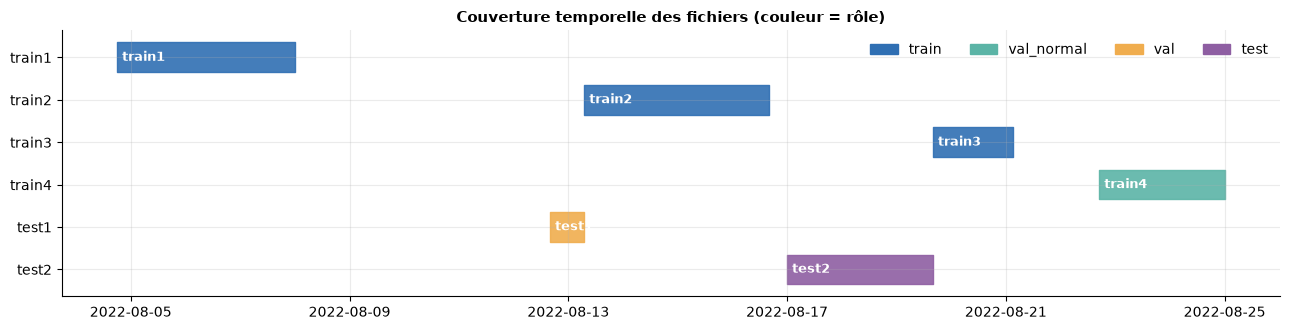

💡 [Fuite] Aucun chevauchement temporel entre fichiers ✔


In [7]:
fig, ax = plt.subplots(figsize=(13, 3.4))
for i, (k, v) in enumerate(raw.items()):
    s, e = mdates.date2num(v.timestamp.min()), mdates.date2num(v.timestamp.max())
    ax.broken_barh([(s, max(e - s, .01))], (i - .35, .7), color=PALETTE[ROLE_OF[k]], alpha=.9)
    ax.text(s, i, f" {k}", va="center", ha="left", fontsize=9, color="white", fontweight="bold")
ax.set_yticks(range(len(raw))); ax.set_yticklabels(list(raw)); ax.xaxis_date(); ax.invert_yaxis()
ax.set_title("Couverture temporelle des fichiers (couleur = rôle)")
ax.legend(handles=[Patch(color=PALETTE[r], label=r) for r in ("train", "val_normal", "val", "test")], loc="upper right", ncol=4, frameon=False)
savefig("01_couverture_temporelle")
overlap = [(a, b) for a in raw for b in raw if a < b and raw[a].timestamp.min() <= raw[b].timestamp.max() and raw[b].timestamp.min() <= raw[a].timestamp.max()]
insight("Fuite", "Aucun chevauchement temporel entre fichiers ✔" if not overlap else f"Chevauchements temporels détectés : {overlap} ⚠ (risque de fuite)")

### 4.3 Ordre chronologique réel : les sessions HAI sont **entrelacées** dans le temps
Le protocole « sessions » est sans chevauchement mais **n'est pas strictement chronologique**. C'est un fait à présenter tel quel dans le rapport. Deux protocoles répondent à deux questions différentes :

| Protocole | Question | Forces / limites |
|---|---|---|
| **`sessions`** (défaut) | Le modèle généralise-t-il à des **sessions industrielles différentes** ? | beaucoup de données d'apprentissage (train1-3), mais train3/train4 sont postérieurs au test final : le modèle voit du « futur normal » |
| **`chrono`** | Que se passe-t-il si l'on **met en production** à la date du test ? | train, validation et seuil strictement antérieurs au test final ; moins de données ; train3 + train4 deviennent un **flux de production** simulé (démo de drift, F18-F22) |

Les deux sont produits et sauvegardés. L'écart de performance entre eux (hypothèse H1, Phase 2) mesure le **coût de la généralisation dans le temps**.

In [8]:
order = pd.DataFrame({k: {"début": v.timestamp.min(), "fin": v.timestamp.max(), "rôle (sessions)": ROLE_OF[k]} for k, v in raw.items()}).T.sort_values("début")
t1s, t1e, t2s, t2e = raw["test1"].timestamp.min(), raw["test1"].timestamp.max(), raw["test2"].timestamp.min(), raw["test2"].timestamp.max()
order["antérieur au test2 ?"] = order["fin"] < t2s
display(order)
TR_FILES = ("train1", "train2", "train3", "train4")
after_t2 = [k for k in TR_FILES if raw[k].timestamp.min() > t2e]
before_t1 = [k for k in TR_FILES if raw[k].timestamp.max() < t1s]; after_t1 = [k for k in TR_FILES if raw[k].timestamp.min() > t1e]
insight("Chronologie", f"Protocole « sessions » : {after_t2} sont POSTÉRIEURS au test final (test2) ; test1 se situe entre {before_t1} et {after_t1}. Ce n'est donc PAS un découpage chronologique strict : il mesure la généralisation entre sessions, pas une mise en production.")
insight("Chronologie", "Protocole « chrono » : train = train1 + train2 (sans ses dernières heures), val_normal = ces heures, val = test1, test = test2 ; train3 + train4 (postérieurs) = flux de production simulé.")
srt = order.reset_index().rename(columns={"index": "fichier"})
adj = [(a, b, (srt.loc[i + 1, "début"] - srt.loc[i, "fin"]).total_seconds()) for i, (a, b) in enumerate(zip(srt["fichier"][:-1], srt["fichier"][1:]))]
contig = [(a, b, g) for a, b, g in adj if g <= 5]
if contig: insight("Chronologie", f"Fichiers contigus dans le temps (écart ≤ 5 s) : {contig}. L'état du procédé se prolonge d'un fichier à l'autre : à garder en tête pour la frontière entre jeux.")

,début,fin,rôle (sessions),antérieur au test2 ?
train1,2022-08-04 18:00:01,2022-08-08 00:00:00,train,True
test1,2022-08-12 16:00:01,2022-08-13 07:00:00,val,True
train2,2022-08-13 07:00:01,2022-08-16 16:00:00,train,True
test2,2022-08-17 00:00:01,2022-08-19 16:00:00,test,False
train3,2022-08-19 16:00:01,2022-08-21 03:00:00,train,False
train4,2022-08-22 17:00:01,2022-08-25 00:00:00,val_normal,False


💡 [Chronologie] Protocole « sessions » : ['train3', 'train4'] sont POSTÉRIEURS au test final (test2) ; test1 se situe entre ['train1'] et ['train2', 'train3', 'train4']. Ce n'est donc PAS un découpage chronologique strict : il mesure la généralisation entre sessions, pas une mise en production.
💡 [Chronologie] Protocole « chrono » : train = train1 + train2 (sans ses dernières heures), val_normal = ces heures, val = test1, test = test2 ; train3 + train4 (postérieurs) = flux de production simulé.
💡 [Chronologie] Fichiers contigus dans le temps (écart ≤ 5 s) : [('test1', 'train2', 1.0), ('test2', 'train3', 1.0)]. L'état du procédé se prolonge d'un fichier à l'autre : à garder en tête pour la frontière entre jeux.


## 5. Dictionnaire des variables (tags)
**Pourquoi.** 86 variables anonymes ne se pilotent pas. On structure le catalogue par **processus** (préfixe `P1_`…`P4_`) et par **type physique** (heuristique sur le nom) pour :
- interpréter les variables contributrices à une anomalie (F8) ;
- construire des alertes lisibles pour l'ingénieur (F30) ;
- guider le feature engineering (F3).

> ⚠ La classification par type est **heuristique** (basée sur les conventions de nommage observées : `FT/FIT` débit, `PIT` pression, `TIT` température, `LIT` niveau, `FCV/PCV/LCV` vannes, `PP` pompes, `SIT/VT` vitesse-vibration, suffixe `D` = commande, `Z` = retour de position, `SP` = consigne). Elle doit être confrontée au document officiel *hai_dataset_technical_details.pdf*.

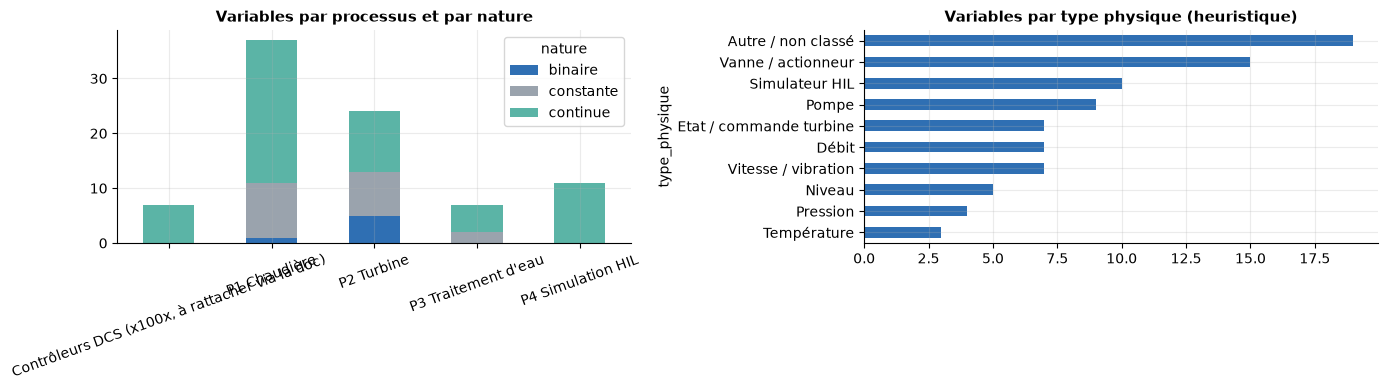

processus,"Contrôleurs DCS (x100x, à rattacher via la doc)",P1 Chaudière,P2 Turbine,P3 Traitement d'eau,P4 Simulation HIL
n_variables,7,37,24,7,11


,tag,processus,type_physique,nature,valeurs_distinctes
0,P1_FCV01D,P1 Chaudière,Vanne / actionneur,continue,627853
1,P1_FCV01Z,P1 Chaudière,Vanne / actionneur,continue,10278
2,P1_FCV02D,P1 Chaudière,Vanne / actionneur,continue,13568
3,P1_FCV02Z,P1 Chaudière,Vanne / actionneur,continue,9769
4,P1_FCV03D,P1 Chaudière,Vanne / actionneur,continue,498971
5,P1_FCV03Z,P1 Chaudière,Vanne / actionneur,continue,2315
6,P1_FT01,P1 Chaudière,Débit,continue,810
7,P1_FT01Z,P1 Chaudière,Débit,continue,809
8,P1_FT02,P1 Chaudière,Débit,continue,13106
9,P1_FT02Z,P1 Chaudière,Débit,continue,13100


In [9]:
PROC_NAME = {"P1": "P1 Chaudière", "P2": "P2 Turbine", "P3": "P3 Traitement d'eau", "P4": "P4 Simulation HIL", "DCS": "Contrôleurs DCS (x100x, à rattacher via la doc)", "Autre": "Autre"}
TYPE_RULES = [(r"^(FCV|PCV|LCV|TCV|SOL)", "Vanne / actionneur"), (r"^(FT|FIT)", "Débit"), (r"^(PIT|PT)", "Pression"),
              (r"^(TIT|TT)", "Température"), (r"^(LIT|LT|LH|LL|LCP)", "Niveau"), (r"^PP", "Pompe"), (r"^(SIT|VT|VXT|VYT|CO_|RTR)", "Vitesse / vibration"),
              (r"^B\d", "Variable de boucle DCS"), (r"^(HT_|ST_)", "Simulateur HIL"), (r"^(OnOff|AutoGO|ManualGO|Emerg|MSD|TripEx|24Vdc|ATSW)", "Etat / commande turbine")]
def process_of(tag):
    m = re.match(r"P(\d)_", tag)
    if m: return f"P{m.group(1)}"
    return "DCS" if re.match(r"^x\d{4}_", tag) else "Autre"
def type_of(tag):
    body = re.sub(r"^P\d_", "", tag)
    return next((lab for pat, lab in TYPE_RULES if re.match(pat, body)), "Autre / non classé")

TR = pd.concat([raw[k] for k in ("train1", "train2", "train3")], ignore_index=True)       # train = fichiers 1 à 3
all_tags = sensor_cols(TR)
nun = TR[all_tags].nunique()
def kind_of(c):
    n = nun[c]
    return "constante" if n <= 1 else "binaire" if n == 2 else "discrète (≤10)" if n <= 10 else "continue"
tags = pd.DataFrame({"tag": all_tags}); tags["processus"] = tags.tag.map(lambda t: PROC_NAME[process_of(t)])
tags["type_physique"] = tags.tag.map(type_of); tags["nature"] = tags.tag.map(kind_of); tags["valeurs_distinctes"] = tags.tag.map(nun)
KIND = dict(zip(tags.tag, tags.nature))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
tags.groupby(["processus", "nature"]).size().unstack(fill_value=0).plot.bar(stacked=True, ax=axes[0], rot=20, color=["#2f6fb3", "#9aa3ad", "#5bb4a6", "#f0ad4e"][:tags.nature.nunique()])
axes[0].set_title("Variables par processus et par nature"); axes[0].set_xlabel("")
tags.type_physique.value_counts().sort_values().plot.barh(ax=axes[1], color="#2f6fb3"); axes[1].set_title("Variables par type physique (heuristique)")
savefig("02_dictionnaire_variables")
display(tags.groupby("processus").agg(n_variables=("tag", "size")).T)
tags.head(15)

In [10]:
nc = (tags.nature == "constante").sum(); nb = (tags.nature == "binaire").sum(); nd = (tags.nature == "discrète (≤10)").sum(); ncont = (tags.nature == "continue").sum()
insight("Variables", f"{len(tags)} variables : {ncont} continues, {nb} binaires, {nd} discrètes, {nc} constantes sur le train.")
if nc: insight("Variables", f"Variables constantes (aucune information, à exclure) : {tags[tags.nature=='constante'].tag.tolist()}")
if nb + nd: insight("Variables", "Les variables binaires/discrètes (états de pompes, modes) ne se normalisent pas comme des mesures continues : elles seront conservées mais leur traitement (encodage, features d'événements) est à revoir en Phase 2 / F3.")
share = tags.processus.value_counts(normalize=True).round(2).to_dict()
insight("Variables", f"Répartition par processus : {share}")

💡 [Variables] 86 variables : 60 continues, 6 binaires, 0 discrètes, 20 constantes sur le train.
💡 [Variables] Variables constantes (aucune information, à exclure) : ['P1_PIT01_HH', 'P1_PP01AD', 'P1_PP01AR', 'P1_PP01BD', 'P1_PP01BR', 'P1_PP02D', 'P1_PP02R', 'P1_SOL01D', 'P1_SOL03D', 'P1_STSP', 'P2_Emerg', 'P2_OnOff', 'P2_RTR', 'P2_TripEx', 'P2_VTR01', 'P2_VTR02', 'P2_VTR03', 'P2_VTR04', 'P3_LH01', 'P3_LL01']
💡 [Variables] Les variables binaires/discrètes (états de pompes, modes) ne se normalisent pas comme des mesures continues : elles seront conservées mais leur traitement (encodage, features d'événements) est à revoir en Phase 2 / F3.
💡 [Variables] Répartition par processus : {'P1 Chaudière': 0.43, 'P2 Turbine': 0.28, 'P4 Simulation HIL': 0.13, "P3 Traitement d'eau": 0.08, 'Contrôleurs DCS (x100x, à rattacher via la doc)': 0.08}


## 6. EDA univariée
**Pourquoi.** Connaître la forme des distributions (échelle, asymétrie, queues lourdes, valeurs discrètes) conditionne le choix de la normalisation, du traitement des aberrants et même de la fonction de perte des modèles (une erreur quadratique est très sensible aux queues lourdes).

**Ce qu'on regarde :** statistiques descriptives · asymétrie (*skewness*) · aplatissement (*kurtosis*) · histogrammes.

,mean,std,min,max,skew,kurtosis
P1_FCV01D,32.759,25.417,0.000,92.239,0.348,-1.397
P1_FCV01Z,32.609,25.708,0.314,92.195,0.339,-1.398
P1_FCV02D,44.558,40.187,15.000,100.000,0.639,-1.578
P1_FCV02Z,40.312,37.377,12.292,97.597,0.779,-1.270
P1_FCV03D,54.832,3.230,47.687,67.139,0.864,0.589
P1_FCV03Z,55.534,3.310,48.334,68.262,0.859,0.557
P1_FT01,62.660,7.720,0.801,198.784,1.175,14.086
P1_FT01Z,326.235,39.991,4.171,892.227,0.980,10.404
P1_FT02,1085.486,1043.517,1.183,2506.676,0.269,-1.726
P1_FT02Z,1654.728,1285.854,6.157,3190.000,-0.054,-1.687


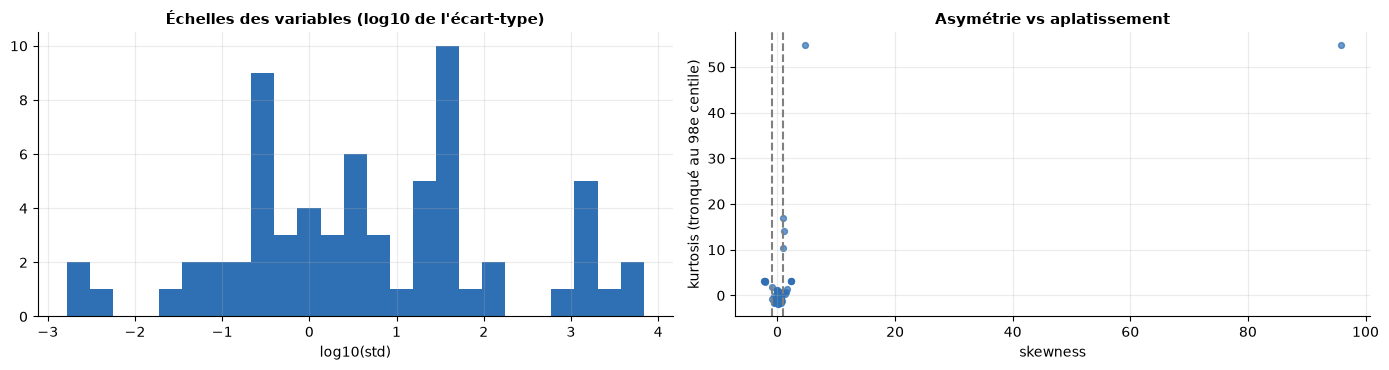

In [11]:
FEATS_NC = [c for c in all_tags if nun[c] > 1 and c not in EXCLUDE_COLUMNS]          # variables non constantes
CONT = [c for c in FEATS_NC if KIND[c] == "continue"]
TRS = TR.sample(min(SAMPLE_N, len(TR)), random_state=SEED).sort_index()               # sous-échantillon pour les graphiques

desc = TR[FEATS_NC].describe().T
desc["skew"] = TR[FEATS_NC].skew(); desc["kurtosis"] = TR[FEATS_NC].kurt(); desc["CV"] = desc["std"] / desc["mean"].abs().replace(0, np.nan)
display(desc[["mean", "std", "min", "max", "skew", "kurtosis"]].round(3).head(15))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].hist(np.log10(desc["std"].replace(0, np.nan).dropna()), bins=25, color=PALETTE["train"]); ax[0].set_title("Échelles des variables (log10 de l'écart-type)"); ax[0].set_xlabel("log10(std)")
ax[1].scatter(desc["skew"], desc["kurtosis"].clip(upper=desc["kurtosis"].quantile(.98)), s=18, alpha=.7, color=PALETTE["train"])
ax[1].axvline(1, ls="--", c="grey"); ax[1].axvline(-1, ls="--", c="grey"); ax[1].set_title("Asymétrie vs aplatissement"); ax[1].set_xlabel("skewness"); ax[1].set_ylabel("kurtosis (tronqué au 98e centile)")
savefig("03_echelles_forme")

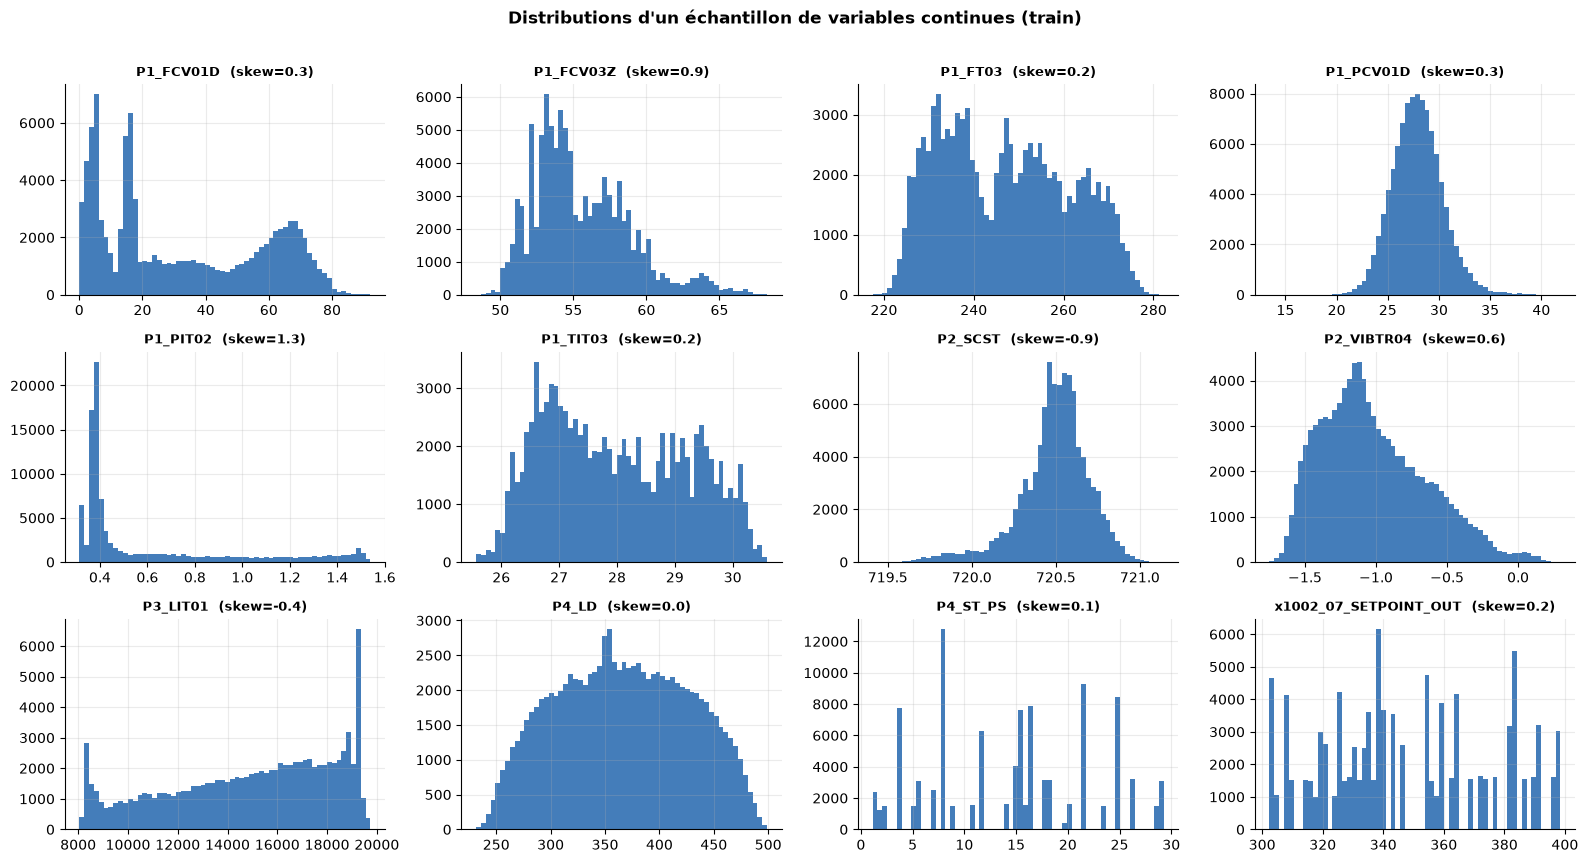

In [12]:
sel = CONT[::max(1, len(CONT) // 12)][:12]
fig, axes = plt.subplots(3, 4, figsize=(16, 8.5)); axes = axes.ravel()
for ax, c in zip(axes, sel):
    ax.hist(TRS[c].dropna(), bins=60, color=PALETTE["train"], alpha=.9); ax.set_title(f"{c}  (skew={desc.loc[c, 'skew']:.1f})", fontsize=9)
for ax in axes[len(sel):]: ax.set_visible(False)
fig.suptitle("Distributions d'un échantillon de variables continues (train)", y=1.01, fontweight="bold")
savefig("04_histogrammes")

In [13]:
scale_ratio = desc["std"].max() / max(desc["std"][desc["std"] > 0].min(), 1e-12)
skewed = (desc["skew"].abs() > 1).mean(); heavy = (desc["kurtosis"] > 10).mean()
insight("Échelles", f"Les écarts-types varient d'un facteur ~{scale_ratio:,.0f} entre variables → normalisation indispensable (sans elle, les variables à grande échelle dominent l'erreur de reconstruction).")
insight("Forme", f"{skewed:.0%} des variables ont |skewness|>1 et {heavy:.0%} ont une kurtosis>10 (queues lourdes).")
if skewed > .3: insight("Forme", "Beaucoup de distributions asymétriques : StandardScaler reste utilisable, mais un RobustScaler / une transformation log est une piste d'amélioration à tester en Phase 2.")

💡 [Échelles] Les écarts-types varient d'un facteur ~4,151,182 entre variables → normalisation indispensable (sans elle, les variables à grande échelle dominent l'erreur de reconstruction).
💡 [Forme] 21% des variables ont |skewness|>1 et 8% ont une kurtosis>10 (queues lourdes).


**Décision (provisoire).** Normalisation **z-score** ajustée sur le train uniquement. Une alternative robuste (médiane/IQR) sera comparée en Phase 2 si les modèles sont sensibles aux queues lourdes.

## 7. EDA temporelle
**Pourquoi.** Ce sont des **séries temporelles** : la continuité, la régularité d'échantillonnage, la stationnarité et la mémoire (autocorrélation) dictent le découpage, le feature engineering (F3) et surtout la **taille des fenêtres** (F4 : 10 / 30 / 60 s).

### 7.1 Régularité de l'échantillonnage

,% Δt = 1 s,Δt max (s),nb trous (>1 s),secondes manquantes,Δt <= 0 (doublons/désordre)
train1,100.0,1.0,0.0,0.0,0.0
train2,100.0,1.0,0.0,0.0,0.0
train3,100.0,1.0,0.0,0.0,0.0
train4,100.0,1.0,0.0,0.0,0.0
test1,100.0,1.0,0.0,0.0,0.0
test2,100.0,1.0,0.0,0.0,0.0


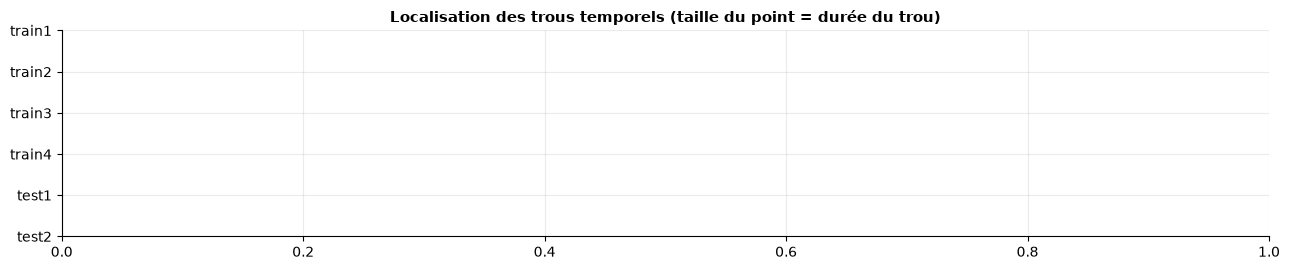

💡 [Continuité] 0 trous au total (0 s manquantes) et 0 pas de temps nuls/négatifs. Données quasi parfaitement régulières ✔


In [14]:
dts = {k: v.timestamp.sort_values().diff().dt.total_seconds().dropna() for k, v in raw.items()}
reg = pd.DataFrame({k: {"% Δt = 1 s": round(100 * (d == FREQ_S).mean(), 3), "Δt max (s)": d.max(), "nb trous (>1 s)": int((d > FREQ_S).sum()),
                        "secondes manquantes": float((d[d > FREQ_S] - FREQ_S).sum()), "Δt <= 0 (doublons/désordre)": int((d <= 0).sum())} for k, d in dts.items()}).T
display(reg)
fig, ax = plt.subplots(figsize=(13, 2.8))
for i, (k, d) in enumerate(dts.items()):
    g = d[d > FREQ_S]
    if len(g): ax.scatter(raw[k].timestamp.sort_values().iloc[1:][d.values > FREQ_S], [i] * len(g), s=20 + 4 * g.values, color=PALETTE["attack"], alpha=.7)
ax.set_yticks(range(len(dts))); ax.set_yticklabels(list(dts)); ax.invert_yaxis(); ax.set_title("Localisation des trous temporels (taille du point = durée du trou)")
savefig("05_trous_temporels")
tot_gap = reg["secondes manquantes"].sum(); tot_dup = reg["Δt <= 0 (doublons/désordre)"].sum()
insight("Continuité", f"{int(reg['nb trous (>1 s)'].sum())} trous au total ({tot_gap:,.0f} s manquantes) et {int(tot_dup)} pas de temps nuls/négatifs." + (" Données quasi parfaitement régulières ✔" if tot_gap == 0 and tot_dup == 0 else " Un nettoyage temporel est nécessaire (section 13)."))

### 7.2 Stationnarité : le comportement « normal » est-il stable dans le temps ?

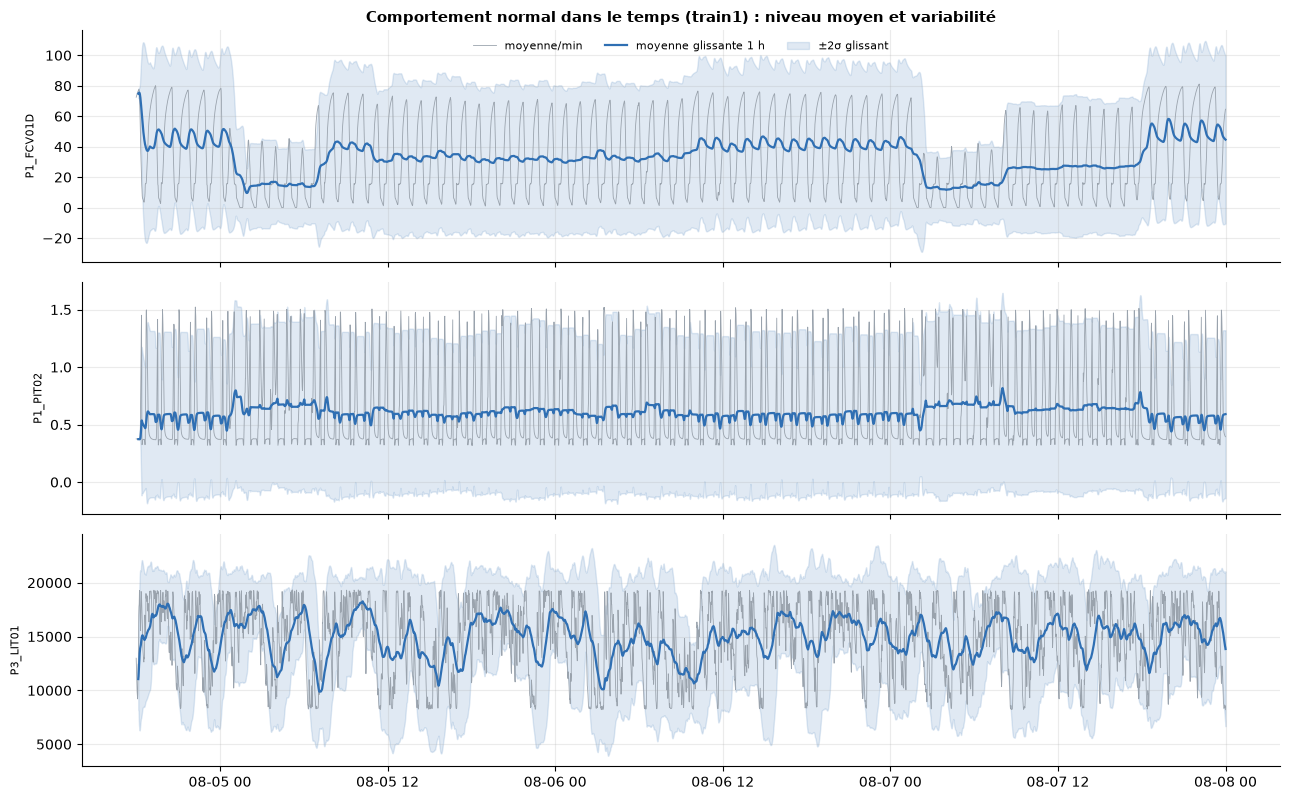

💡 [Stationnarité] 35 variables sur 66 changent de plus de 0,5σ entre le début et la fin de train1 (max : P4_ST_FD = 1491.02σ).
💡 [Stationnarité] Le « normal » n'est donc pas un point fixe : il dépend du régime de fonctionnement. Un modèle entraîné sur un régime peut sur-alerter sur un autre → justifie le monitoring de drift (F18) et le réentraînement contrôlé (F22).


In [15]:
t1 = raw["train1"].set_index("timestamp"); show = CONT[:: max(1, len(CONT) // 3)][:3]
fig, axes = plt.subplots(len(show), 1, figsize=(13, 2.7 * len(show)), sharex=True)
for ax, c in zip(np.atleast_1d(axes), show):
    s = t1[c].resample("60s").mean(); ax.plot(s.index, s, lw=.6, color=PALETTE["grey"], label="moyenne/min")
    ax.plot(s.index, s.rolling(60, min_periods=10).mean(), lw=1.6, color=PALETTE["train"], label="moyenne glissante 1 h")
    ax.fill_between(s.index, s.rolling(60, min_periods=10).mean() - 2 * s.rolling(60, min_periods=10).std(), s.rolling(60, min_periods=10).mean() + 2 * s.rolling(60, min_periods=10).std(), alpha=.15, color=PALETTE["train"], label="±2σ glissant")
    ax.set_ylabel(c, fontsize=8)
np.atleast_1d(axes)[0].legend(ncol=3, frameon=False, fontsize=8); np.atleast_1d(axes)[0].set_title("Comportement normal dans le temps (train1) : niveau moyen et variabilité")
savefig("06_stationnarite")

thirds = np.array_split(t1[FEATS_NC], 3)
shift = ((thirds[2].mean() - thirds[0].mean()) / t1[FEATS_NC].std().replace(0, np.nan)).abs().dropna().sort_values(ascending=False)
insight("Stationnarité", f"{(shift > .5).sum()} variables sur {len(shift)} changent de plus de 0,5σ entre le début et la fin de train1 (max : {shift.index[0]} = {shift.iloc[0]:.2f}σ).")
insight("Stationnarité", "Le « normal » n'est donc pas un point fixe : il dépend du régime de fonctionnement. Un modèle entraîné sur un régime peut sur-alerter sur un autre → justifie le monitoring de drift (F18) et le réentraînement contrôlé (F22)." if (shift > .5).mean() > .1 else "Comportement normal globalement stable sur la durée de train1 ✔")

### 7.3 Mémoire du signal : autocorrélation → choix des fenêtres (lien direct avec F4)
Si une variable est fortement corrélée à ses valeurs passées sur ~*L* secondes, une fenêtre de taille ≈ *L* capture sa dynamique ; une fenêtre bien plus longue ajoute surtout du bruit et du coût.

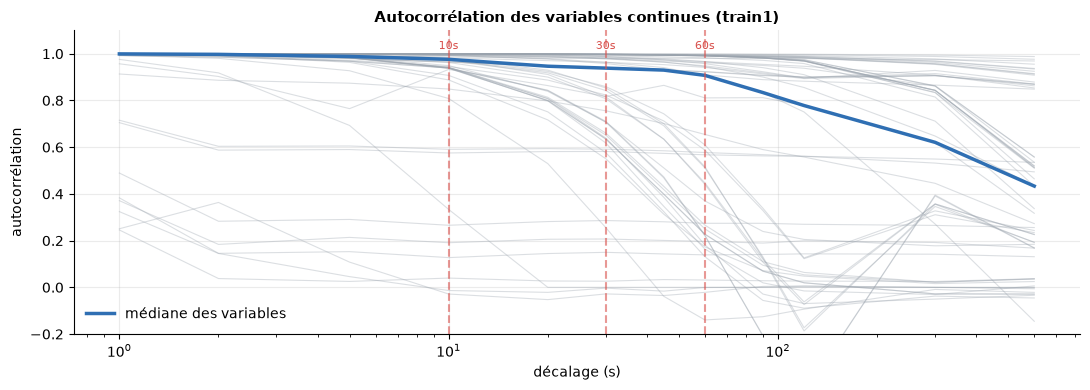

💡 [Fenêtres] Autocorrélation médiane à 10 s = 0.98, à 30 s = 0.94, à 60 s = 0.91 ; elle passe sous 0,5 vers 600 s.
💡 [Fenêtres] Signaux très persistants : les valeurs successives sont presque redondantes. Des features de **variation** (différences, dérivées) apporteront plus d'information que la valeur brute ; fenêtres 30–60 s à privilégier pour le LSTM-AE.


In [16]:
seg = raw["train1"][CONT].iloc[:min(100_000, len(raw["train1"]))]
LAGS = [1, 2, 5, 10, 20, 30, 45, 60, 90, 120, 300, 600]
acf = pd.DataFrame({c: [seg[c].autocorr(l) for l in LAGS] for c in CONT}, index=LAGS)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(LAGS, acf, color=PALETTE["grey"], alpha=.35, lw=.8); ax.plot(LAGS, acf.median(axis=1), color=PALETTE["train"], lw=2.5, label="médiane des variables")
for w in (10, 30, 60): ax.axvline(w, ls="--", c=PALETTE["attack"], alpha=.6); ax.text(w, 1.02, f"{w}s", ha="center", color=PALETTE["attack"], fontsize=8)
ax.set_xscale("log"); ax.set_ylim(-.2, 1.1); ax.set_xlabel("décalage (s)"); ax.set_ylabel("autocorrélation"); ax.legend(frameon=False); ax.set_title("Autocorrélation des variables continues (train1)")
savefig("07_autocorrelation")
med = acf.median(axis=1); l50 = next((l for l in LAGS if med[l] < .5), None)
insight("Fenêtres", f"Autocorrélation médiane à 10 s = {med[10]:.2f}, à 30 s = {med[30]:.2f}, à 60 s = {med[60]:.2f}" + (f" ; elle passe sous 0,5 vers {l50} s." if l50 else " ; elle reste >0,5 sur tout l'horizon testé (signaux très lents)."))
insight("Fenêtres", "Signaux très persistants : les valeurs successives sont presque redondantes. Des features de **variation** (différences, dérivées) apporteront plus d'information que la valeur brute ; fenêtres 30–60 s à privilégier pour le LSTM-AE." if med[30] > .8 else "Mémoire modérée : fenêtres courtes (10–30 s) suffisantes, à confirmer expérimentalement (F4).")

## 8. EDA multivariée : corrélations et dimension intrinsèque
**Pourquoi.** Une anomalie industrielle est souvent une **rupture de relation entre variables** (ex. la pression monte alors que le débit baisse) plutôt qu'un dépassement de seuil isolé. Si les variables sont fortement liées, un modèle multivarié (Autoencoder) peut apprendre ces relations ; les dépassements de relation deviennent alors le signal d'anomalie (F9).

### 8.1 Matrice de corrélation (ordonnée par classification hiérarchique)

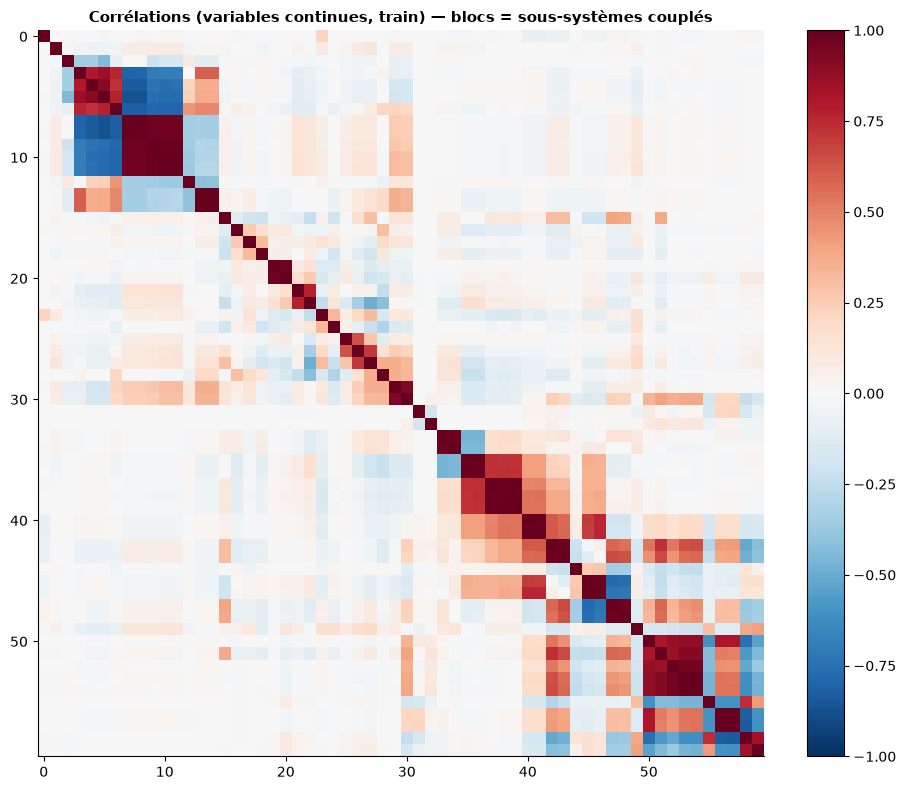

25 paires avec |corr| > 0.95


,a,b,corr,|corr|
542,P1_FT02Z,x1003_10_SETPOINT_OUT,0.9997,0.9997
1132,P1_TIT01,P4_ST_TT01,0.9997,0.9997
1693,P4_ST_GOV,P4_ST_PO,0.9993,0.9993
1563,P3_LCV01D,P4_HT_PO,0.9990,0.9990
0,P1_FCV01D,P1_FCV01Z,0.9986,0.9986
545,P1_FT03,P1_FT03Z,0.9964,0.9964
339,P1_FT01,P1_FT01Z,0.9943,0.9943
638,P1_FT03Z,x1002_08_SETPOINT_OUT,0.9900,0.9900
230,P1_FCV03D,P1_FCV03Z,0.9890,0.9890
590,P1_FT03,x1002_08_SETPOINT_OUT,0.9872,0.9872


In [17]:
S = TRS[CONT]; S = S.fillna(S.median())
corr = S.corr(); dist = np.array((1 - corr.abs()).fillna(1), dtype=float); np.fill_diagonal(dist, 0); dist = (dist + dist.T) / 2
order = leaves_list(linkage(squareform(dist, checks=False), method="average")); corr_o = corr.iloc[order, order]
fig, ax = plt.subplots(figsize=(9.5, 8)); im = ax.imshow(corr_o, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
if len(corr_o) <= 45: ax.set_xticks(range(len(corr_o))); ax.set_xticklabels(corr_o.columns, rotation=90, fontsize=7); ax.set_yticks(range(len(corr_o))); ax.set_yticklabels(corr_o.columns, fontsize=7)
plt.colorbar(im, ax=ax, fraction=.046); ax.set_title("Corrélations (variables continues, train) — blocs = sous-systèmes couplés")
savefig("08_correlations")

iu = np.triu_indices_from(corr, 1); pairs = pd.DataFrame({"a": corr.columns[iu[0]], "b": corr.columns[iu[1]], "corr": corr.values[iu]})
pairs["|corr|"] = pairs["corr"].abs(); high = pairs[pairs["|corr|"] > CORR_THRESHOLD].sort_values("|corr|", ascending=False)
print(f"{len(high)} paires avec |corr| > {CORR_THRESHOLD}"); display(high.head(12).round(4))

In [18]:
mean_abs = (corr.abs().sum() - 1) / (len(corr) - 1)
insight("Corrélations", f"|corrélation| moyenne entre variables : {mean_abs.mean():.2f} ; {len(high)} paires dépassent {CORR_THRESHOLD} (quasi-redondantes).")
red_vars = set(high["b"])
insight("Corrélations", f"{len(red_vars)} variables sont quasi-redondantes avec une autre. Décision : " + ("les supprimer." if DROP_CORRELATED else "les CONSERVER (DROP_CORRELATED=False) : pour un Autoencoder, la redondance fait partie de la structure « normale » apprise ; une rupture de cette redondance est un signal d'attaque (ex. consigne vs retour de position)."))

💡 [Corrélations] |corrélation| moyenne entre variables : 0.12 ; 25 paires dépassent 0.95 (quasi-redondantes).
💡 [Corrélations] 17 variables sont quasi-redondantes avec une autre. Décision : les CONSERVER (DROP_CORRELATED=False) : pour un Autoencoder, la redondance fait partie de la structure « normale » apprise ; une rupture de cette redondance est un signal d'attaque (ex. consigne vs retour de position).


### 8.1b Corrélations sur les **variations** (différences à 1 s)
Deux signaux lents peuvent être corrélés uniquement parce qu'ils dérivent ensemble (corrélation de tendance). En corrélant les **variations**, on isole le couplage *dynamique* : c'est lui qui sera perturbé par une attaque.

In [19]:
D = raw["train1"][CONT].iloc[:200_000].diff().dropna(); D = D.loc[:, D.std() > 0]
cd = D.corr(); iu2 = np.triu_indices_from(cd, 1)
pd_ = pd.DataFrame({"a": cd.columns[iu2[0]], "b": cd.columns[iu2[1]], "corr_variations": cd.values[iu2]}); pd_["|corr|"] = pd_["corr_variations"].abs()
mean_levels, mean_diffs = (corr.abs().sum().sum() - len(corr)) / (len(corr) ** 2 - len(corr)), (cd.abs().sum().sum() - len(cd)) / (len(cd) ** 2 - len(cd))
display(pd_.sort_values("|corr|", ascending=False).head(10).round(3))
insight("Couplage dynamique", f"|corrélation| moyenne : {mean_levels:.2f} sur les niveaux vs {mean_diffs:.2f} sur les variations. Paires les plus couplées dynamiquement : " + ", ".join(f"{r.a}~{r.b} ({r.corr_variations:+.2f})" for r in pd_.sort_values("|corr|", ascending=False).head(3).itertuples()) + ".")
insight("Couplage dynamique", "Les relations dynamiques sont concentrées sur quelques paires/blocs (commande ↔ retour, consigne ↔ mesure) plutôt que réparties sur toutes les variables : l'Autoencoder devra surtout apprendre ces relations locales, et l'explicabilité (F8) pointera naturellement vers elles." if mean_diffs < .15 else "Couplage dynamique diffus entre de nombreuses variables : un modèle multivarié global est justifié.")

,a,b,corr_variations,|corr|
1634,P4_ST_GOV,P4_ST_PO,0.914,0.914
8,P1_FCV01D,P1_FT02Z,-0.909,0.909
1700,x1001_15_ASSIGN_OUT,x1003_24_SUM_OUT,0.891,0.891
1504,P3_LCV01D,P4_HT_PO,0.812,0.812
1387,P2_VIBTR03,P2_VT01,-0.811,0.811
1334,P2_VIBTR01,P2_VIBTR03,0.775,0.775
1645,P4_ST_LD,P4_ST_PO,0.736,0.736
1660,P4_ST_PO,x1001_15_ASSIGN_OUT,0.720,0.720
1665,P4_ST_PO,x1003_24_SUM_OUT,0.717,0.717
1633,P4_ST_GOV,P4_ST_LD,0.696,0.696


💡 [Couplage dynamique] |corrélation| moyenne : 0.12 sur les niveaux vs 0.03 sur les variations. Paires les plus couplées dynamiquement : P4_ST_GOV~P4_ST_PO (+0.91), P1_FCV01D~P1_FT02Z (-0.91), x1001_15_ASSIGN_OUT~x1003_24_SUM_OUT (+0.89).
💡 [Couplage dynamique] Les relations dynamiques sont concentrées sur quelques paires/blocs (commande ↔ retour, consigne ↔ mesure) plutôt que réparties sur toutes les variables : l'Autoencoder devra surtout apprendre ces relations locales, et l'explicabilité (F8) pointera naturellement vers elles.


### 8.2 Dimension intrinsèque (PCA)
Combien de « degrés de liberté » indépendants contient le comportement normal ? Cela donne un **ordre de grandeur pour la taille du goulot d'étranglement** (espace latent) de l'Autoencoder (F5).

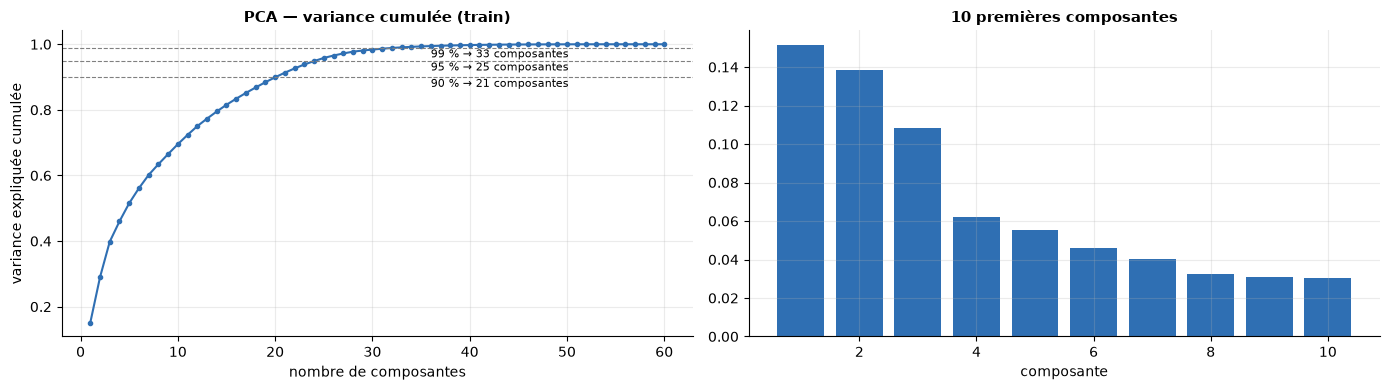

💡 [Dimension] 21 composantes expliquent 90 % de la variance, 25 → 95 %, 33 → 99 % (sur 60 variables continues).
💡 [Dimension] Le comportement normal vit dans un espace d'environ 25 dimensions : un goulot latent de l'ordre de 12–25 neurones est un bon point de départ pour l'Autoencoder.


In [20]:
Xs = StandardScaler().fit_transform(S); pca = PCA().fit(Xs); cum = np.cumsum(pca.explained_variance_ratio_)
n90, n95, n99 = [int(np.searchsorted(cum, q) + 1) for q in (.90, .95, .99)]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(range(1, len(cum) + 1), cum, marker="o", ms=3, color=PALETTE["train"])
for q, n in ((.90, n90), (.95, n95), (.99, n99)): ax[0].axhline(q, ls="--", c="grey", lw=.8); ax[0].text(len(cum) * .6, q - .03, f"{int(q*100)} % → {n} composantes", fontsize=8)
ax[0].set_xlabel("nombre de composantes"); ax[0].set_ylabel("variance expliquée cumulée"); ax[0].set_title("PCA — variance cumulée (train)")
ax[1].bar(range(1, 11), pca.explained_variance_ratio_[:10], color=PALETTE["train"]); ax[1].set_title("10 premières composantes"); ax[1].set_xlabel("composante")
savefig("09_pca_variance")
insight("Dimension", f"{n90} composantes expliquent 90 % de la variance, {n95} → 95 %, {n99} → 99 % (sur {len(CONT)} variables continues).")
insight("Dimension", f"Le comportement normal vit dans un espace d'environ {n95} dimensions : un goulot latent de l'ordre de {max(4, n95 // 2)}–{max(8, n95)} neurones est un bon point de départ pour l'Autoencoder.")

### 8.3 Projection 2D : normal vs attaque (jeu de validation)
Les attaques sont-elles séparables **visuellement** du comportement normal dans l'espace PCA appris sur le train ? (Un chevauchement important est normal : les attaques HAI sont conçues pour être discrètes.)

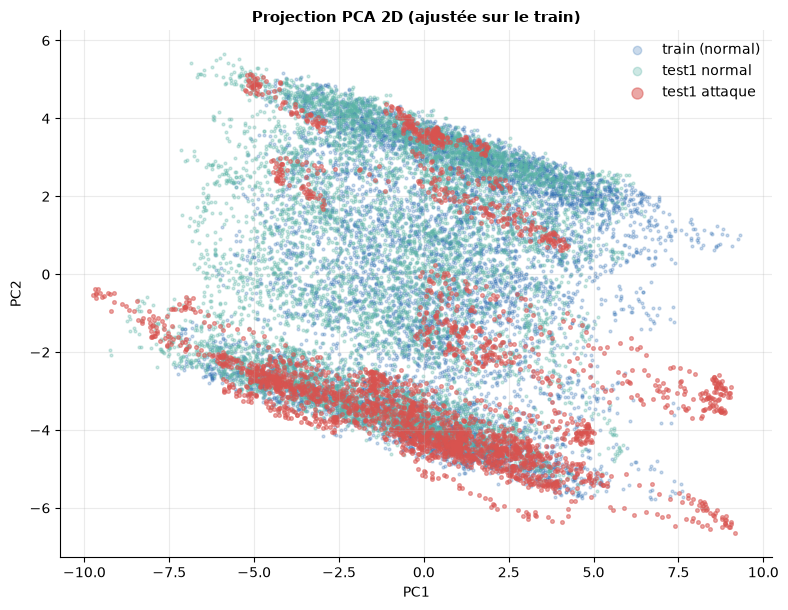

💡 [Séparabilité] Distance (PC1-PC2) du centre au train : test1-normal = 1.35, test1-attaque = 2.15 (rapport 1.6). Séparation PARTIELLE en 2D : les attaques sont un peu plus éloignées du train que le normal de test, mais se chevauchent fortement.


In [21]:
med_tr = S.median(); sc_pca = StandardScaler().fit(S)
V = raw["test1"]; Vn = V[V.label == 0].sample(min(8000, (V.label == 0).sum()), random_state=SEED); Va = V[V.label == 1].sample(min(8000, (V.label == 1).sum()), random_state=SEED)
proj = lambda d: pca.transform(sc_pca.transform(d[CONT].fillna(med_tr)))[:, :2]
P_tr = pca.transform(Xs)[:8000, :2]; P_n, P_a = proj(Vn), proj(Va)
fig, ax = plt.subplots(figsize=(8, 6.2))
ax.scatter(*P_tr.T, s=4, alpha=.25, c=PALETTE["train"], label="train (normal)"); ax.scatter(*P_n.T, s=4, alpha=.3, c=PALETTE["val_normal"], label="test1 normal")
ax.scatter(*P_a.T, s=7, alpha=.5, c=PALETTE["attack"], label="test1 attaque"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(frameon=False, markerscale=3); ax.set_title("Projection PCA 2D (ajustée sur le train)")
savefig("10_pca_projection")
d_n = np.linalg.norm(P_n.mean(0) - P_tr.mean(0)); d_a = np.linalg.norm(P_a.mean(0) - P_tr.mean(0))
ratio_sep = d_a / max(d_n, .05)
verdict = ("Les attaques s'écartent nettement du normal en 2D." if ratio_sep > 2 else
           "Séparation PARTIELLE en 2D : les attaques sont un peu plus éloignées du train que le normal de test, mais se chevauchent fortement." if ratio_sep > 1.3 else
           "Les attaques ne sont PAS séparables en 2D : l'information est dans des dimensions secondaires ou dans la dynamique temporelle → modèles multivariés/temporels justifiés.")
insight("Séparabilité", f"Distance (PC1-PC2) du centre au train : test1-normal = {d_n:.2f}, test1-attaque = {d_a:.2f} (rapport {ratio_sep:.1f}). " + verdict)

## 9. Analyse des attaques (labels)
**Pourquoi.** Les attaques sont la « vérité terrain » : leur nombre, leur durée, leur rareté et la **signature** qu'elles laissent sur les variables déterminent (i) la difficulté de la détection, (ii) les métriques adaptées, (iii) ce que l'explicabilité (F8) devra retrouver.

### 9.1 Segments d'attaque : nombre, durée, espacement

,attaques (segments),officiel,durée médiane (s),durée min (s),durée max (s),% de temps en attaque
test1,14.0,14.0,159.5,56.0,628.0,5.52
test2,38.0,38.0,132.0,61.0,2052.0,3.65


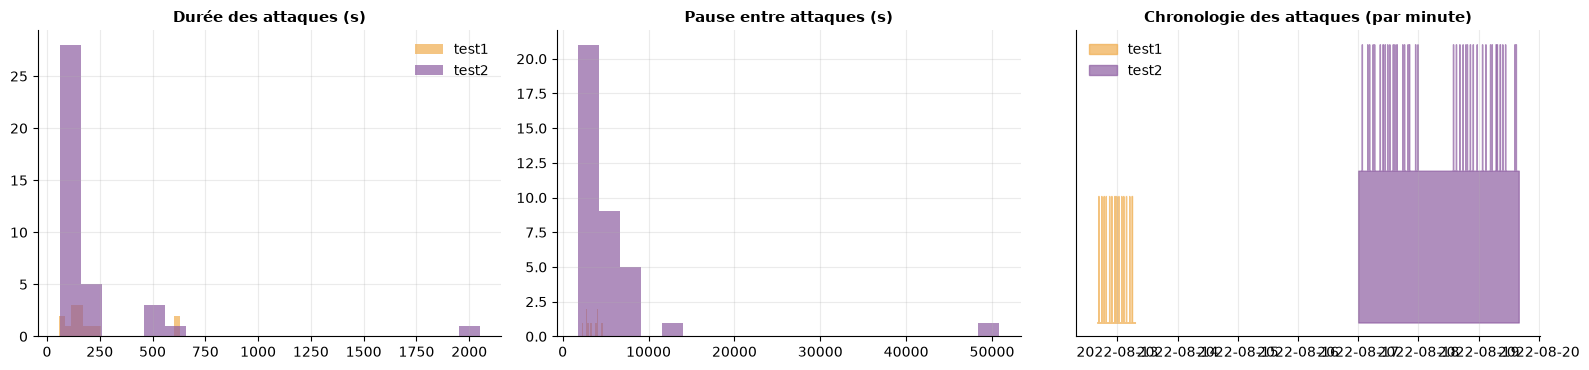

In [22]:
# segments() est importée de src.data.catalog (même code que le pipeline DVC)
SEG = {k: segments(raw[k]) for k in ("test1", "test2")}
summ = pd.DataFrame({k: {"attaques (segments)": len(s), "officiel": EXPECTED_ATTACKS[k], "durée médiane (s)": s["durée_s"].median(), "durée min (s)": s["durée_s"].min(),
                         "durée max (s)": s["durée_s"].max(), "% de temps en attaque": round(100 * raw[k]["label"].mean(), 2)} for k, s in SEG.items()}).T
display(summ)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for k, c in (("test1", PALETTE["val"]), ("test2", PALETTE["test"])): ax[0].hist(SEG[k]["durée_s"], bins=20, alpha=.7, color=c, label=k)
ax[0].set_title("Durée des attaques (s)"); ax[0].legend(frameon=False)
for k, c in (("test1", PALETTE["val"]), ("test2", PALETTE["test"])): ax[1].hist(SEG[k]["pause_avant_s"].dropna(), bins=20, alpha=.7, color=c, label=k)
ax[1].set_title("Pause entre attaques (s)")
for k, c in (("test1", PALETTE["val"]), ("test2", PALETTE["test"])):
    r = raw[k].set_index("timestamp")["label"].resample("60s").max(); ax[2].fill_between(r.index, 0, r.values + (0 if k == "test1" else 1.2), step="mid", alpha=.7, color=c, label=k)
ax[2].set_title("Chronologie des attaques (par minute)"); ax[2].set_yticks([]); ax[2].legend(frameon=False)
savefig("11_attaques_segments")

In [23]:
for k, s in SEG.items():
    off = EXPECTED_ATTACKS[k]
    verdict = ("cohérent ✔" if .6 * off <= len(s) <= 1.5 * off else
               "⚠ MOINS de segments que d'attaques officielles : des attaques consécutives ont probablement fusionné (pas une erreur de labels)" if len(s) < .6 * off else
               "⚠ TROP de segments : labels suspects (alignement ?)")
    insight("Attaques", f"{k} : {len(s)} segments détectés pour {off} attaques officielles — {verdict}")
ratio = {k: raw[k]["label"].mean() for k in SEG}
insight("Déséquilibre", f"Part des secondes en attaque : " + ", ".join(f"{k} = {100*v:.1f} %" for k, v in ratio.items()) + " → classes déséquilibrées : l'accuracy est trompeuse ; on utilisera Precision, Recall, F1 et eTaPR (F11).")
for k, s in SEG.items():
    off = EXPECTED_ATTACKS[k]
    gate(f"labels {k} : nombre d'attaques", 0 < len(s) <= 1.5 * off, f"{len(s)} segments vs {off} officielles (fusions d'attaques consécutives possibles)", hard=STRICT_OFFICIAL_CHECKS)
    if len(s) < .6 * off: gate(f"labels {k} : segments fusionnés ?", False, f"{len(s)} segments seulement : des attaques consécutives ont probablement fusionné", hard=False)
    gate(f"labels {k} : taux d'attaque plausible", .002 < raw[k]["label"].mean() < .30, f"{100*raw[k]['label'].mean():.2f} % des secondes")
short = (pd.concat(SEG.values())["durée_s"] < 30).mean()
if short > 0:
    insight("Détection", f"{short:.0%} des attaques durent moins de 30 s : avec une fenêtre de 60 s, une attaque courte est diluée dans des données normales → le choix de fenêtre (F4) influence directement le **délai de détection** et le rappel.")
else:
    dmin = pd.concat(SEG.values())["durée_s"].min()
    insight("Détection", f"Aucune attaque ne dure moins de 30 s (minimum : {dmin} s) : une fenêtre de 30 s est compatible avec toutes les attaques ; une fenêtre de 60 s peut encore diluer les plus courtes (<60 s) et retarder la détection.")

💡 [Attaques] test1 : 14 segments détectés pour 14 attaques officielles — cohérent ✔
💡 [Attaques] test2 : 38 segments détectés pour 38 attaques officielles — cohérent ✔
💡 [Déséquilibre] Part des secondes en attaque : test1 = 5.5 %, test2 = 3.6 % → classes déséquilibrées : l'accuracy est trompeuse ; on utilisera Precision, Recall, F1 et eTaPR (F11).
✔ labels test1 : nombre d'attaques — 14 segments vs 14 officielles (fusions d'attaques consécutives possibles)
✔ labels test1 : taux d'attaque plausible — 5.52 % des secondes
✔ labels test2 : nombre d'attaques — 38 segments vs 38 officielles (fusions d'attaques consécutives possibles)
✔ labels test2 : taux d'attaque plausible — 3.65 % des secondes
💡 [Détection] Aucune attaque ne dure moins de 30 s (minimum : 56 s) : une fenêtre de 30 s est compatible avec toutes les attaques ; une fenêtre de 60 s peut encore diluer les plus courtes (<60 s) et retarder la détection.


### 9.1b Recoupement avec le catalogue officiel (`summary_label*.txt`)
Les labels de `test2` sont alignés *par position* (timestamps tronqués à la minute). Une concordance à la minute ne prouve **pas** que l'ordre des lignes *à l'intérieur d'une minute* soit correct. Le test décisif est de retrouver, **à la seconde près**, le début et la fin de chaque attaque listée par les auteurs.

In [24]:
CAT, HEAD = {}, {}
for k, fn in (("test1", "summary_label1.txt"), ("test2", "summary_label2.txt")):
    path = FILES["hai-" + k].parent / fn
    if not path.exists():
        gate(f"résumé officiel {k}", False, f"{fn} absent : recoupement impossible", hard=False); continue
    summ, head = parse_summary(path); cc, extra = crosscheck(SEG[k], summ, tol_s=2); CAT[k], HEAD[k] = (summ, cc), head
    gate(f"recoupement {k} : début/fin à ±2 s", bool(cc["ok"].all()) and not extra, f"{int(cc['ok'].sum())}/{len(cc)} attaques concordent ; segments non listés : {extra}", hard=STRICT_OFFICIAL_CHECKS)
    labelled = int(raw[k]["label"].sum())
    gate(f"recoupement {k} : durées", abs(head["total_listed_s"] + len(summ) - labelled) <= 2, f"durées listées + 1 s/attaque = {head['total_listed_s'] + len(summ)} s vs {labelled} s étiquetées", hard=False)
    if head["attacks_header"] is not None and head["attacks_header"] != len(summ):
        insight("Catalogue", f"{k} : l'en-tête officiel annonce {head['attacks_header']} attaques / {head['total_header_s']} s mais le fichier en LISTE {len(summ)} / {head['total_listed_s']} s. Les labels suivent la liste. Incohérence interne du fichier officiel (≈ {head['total_header_s'] - head['total_listed_s']} s non listées) : à citer comme limite ; on ne peut pas exclure des attaques non étiquetées.")
if CAT:
    display(pd.DataFrame({k: v[1][["start_diff_s", "end_diff_s"]].abs().max() for k, v in CAT.items()}).T.rename(columns={"start_diff_s": "écart max début (s)", "end_diff_s": "écart max fin (s)"}))

✔ recoupement test1 : début/fin à ±2 s — 14/14 attaques concordent ; segments non listés : []
✔ recoupement test1 : durées — durées listées + 1 s/attaque = 2981 s vs 2981 s étiquetées
✔ recoupement test2 : début/fin à ±2 s — 38/38 attaques concordent ; segments non listés : []
✔ recoupement test2 : durées — durées listées + 1 s/attaque = 8403 s vs 8403 s étiquetées
💡 [Catalogue] test2 : l'en-tête officiel annonce 40 attaques / 8735 s mais le fichier en LISTE 38 / 8365 s. Les labels suivent la liste. Incohérence interne du fichier officiel (≈ 370 s non listées) : à citer comme limite ; on ne peut pas exclure des attaques non étiquetées.


,écart max début (s),écart max fin (s)
test1,0.0,0.0
test2,0.0,0.0


### 9.2 Signature des attaques — baseline locale **et groupe témoin (placebo)**
**Pourquoi une baseline locale.** Exprimer l'écart en σ *global* du train (version 1) sous-estimait tout : le σ global est gonflé par les changements de régime entre sessions. On mesure donc le changement **par rapport aux 5 minutes précédant l'attaque** :
- **niveau** : (médiane pendant l'attaque − médiane avant) / (écart robuste local avant) ;
- **dynamique** : rapport entre l'écart-type des *variations* (différences à 1 s) pendant et avant.

**Pourquoi un placebo.** Une mesure ne vaut que par sa *distribution nulle*. Avec des écarts locaux très petits (variables lisses, quantifiées ou quasi constantes), n'importe quel changement paraît énorme. On applique donc **exactement la même procédure à des fenêtres NORMALES de même durée** tirées au hasard dans les mêmes fichiers : ce qu'elles « détectent » est du bruit de mesure, pas une attaque. Les seuils sont ensuite **calibrés variable par variable** (99ᵉ centile du placebo).

In [25]:
sd_floor = (TR[FEATS_NC].std() * .02).to_numpy(dtype="float64")      # plancher : évite de diviser par ~0 sur les variables quasi constantes
dsd_floor = raw["train1"][FEATS_NC].iloc[:200_000].diff().std().to_numpy(dtype="float64") * .1 + 1e-12
def signature_for(k, segs, ids):
    df = raw[k]; X = df[FEATS_NC].to_numpy(dtype="float64"); lab = df["label"].to_numpy()
    D = np.vstack([np.full((1, X.shape[1]), np.nan), np.diff(X, axis=0)]); L, R = [], []
    for i0, i1 in segs:
        pre = np.arange(max(0, i0 - LOCAL_PRE_WINDOW_S), i0); pre = pre[lab[pre] == 0]; att = np.arange(i0, i1 + 1)
        if len(pre) < 60:                                   # pas assez de normal juste avant (attaque collée à la précédente ou au début du fichier)
            L.append(np.full(X.shape[1], np.nan)); R.append(np.full(X.shape[1], np.nan)); continue
        med = np.nanmedian(X[pre], axis=0); mad = 1.4826 * np.nanmedian(np.abs(X[pre] - med), axis=0)
        L.append((np.nanmedian(X[att], axis=0) - med) / np.maximum(mad, sd_floor))
        R.append(np.nanstd(D[att], axis=0) / np.maximum(np.nanstd(D[pre], axis=0), dsd_floor))
    return pd.DataFrame(L, index=ids, columns=FEATS_NC), pd.DataFrame(R, index=ids, columns=FEATS_NC)

parts = [signature_for(k, [(int(s.i0), int(s.i1)) for _, s in SEG[k].iterrows()], [f"{k}-A{j+1:02d}" for j in SEG[k].index]) for k in ("test1", "test2")]
LVL, DYN = pd.concat([p[0] for p in parts]), pd.concat([p[1] for p in parts])
valid = LVL.notna().any(axis=1)
print(f"{int(valid.sum())} attaques évaluables sur {len(valid)} ({int((~valid).sum())} sans 60 s de normal juste avant)")

52 attaques évaluables sur 52 (0 sans 60 s de normal juste avant)


In [26]:
# ---- Groupe témoin : fenêtres normales de même durée que chaque attaque (mêmes fichiers) ----
rng_p = np.random.default_rng(SEED)
def placebo_segments(k, n_per):
    lab = raw[k]["label"].to_numpy(); n = len(lab); cs = np.r_[0, np.cumsum(lab)]; out = []
    for _, s in SEG[k].iterrows():
        d, got, tries = int(s["durée_s"]), 0, 0
        while got < n_per and tries < 500:
            tries += 1; i0 = int(rng_p.integers(LOCAL_PRE_WINDOW_S, n - d - 1)); i1 = i0 + d - 1
            if cs[i1 + 1] - cs[i0 - LOCAL_PRE_WINDOW_S] == 0: out.append((i0, i1)); got += 1     # ni la baseline ni la fenêtre ne contiennent d'attaque
    return out
PL = {k: placebo_segments(k, N_PLACEBO) for k in ("test1", "test2")}
pp_ = [signature_for(k, PL[k], [f"{k}-P{j+1:03d}" for j in range(len(PL[k]))]) for k in PL]
LVLp, DYNp = pd.concat([p[0] for p in pp_]), pd.concat([p[1] for p in pp_])
ok_p = LVLp.notna().any(axis=1); LVLp, DYNp = LVLp[ok_p], DYNp[ok_p]
raw_aff_att = ((LVL.abs() > LEVEL_Z) | (DYN > DYN_RATIO)).where(valid, False); raw_aff_pl = (LVLp.abs() > LEVEL_Z) | (DYNp > DYN_RATIO)
n_raw_att, n_raw_pl = raw_aff_att.sum(axis=1)[valid], raw_aff_pl.sum(axis=1)

# ---- Seuils CALIBRÉS variable par variable : au moins LEVEL_Z / DYN_RATIO ET au-dessus du 99e centile du placebo ----
thr_l = np.maximum(LEVEL_Z, LVLp.abs().quantile(.99)); thr_d = np.maximum(DYN_RATIO, DYNp.quantile(.99))
aff = ((LVL.abs() > thr_l) | (DYN > thr_d)).where(valid, False); n_aff = aff.sum(axis=1)
fpr = raw_aff_pl.mean(); att_rate = raw_aff_att[valid].mean()
cmp = pd.DataFrame({"fenêtres placebo": [len(raw_aff_pl), (n_raw_pl > 0).mean(), n_raw_pl.median(), n_raw_pl.max()],
                    "attaques": [int(valid.sum()), (n_raw_att > 0).mean(), n_raw_att.median(), n_raw_att.max()]},
                   index=["effectif", "part avec ≥ 1 variable « affectée » (seuils bruts)", "variables « affectées » : médiane", "variables « affectées » : max"]).round(3)
display(cmp)

,fenêtres placebo,attaques
effectif,260.000,52.0
part avec ≥ 1 variable « affectée » (seuils bruts),0.988,1.0
variables « affectées » : médiane,5.000,8.5
variables « affectées » : max,25.000,33.0


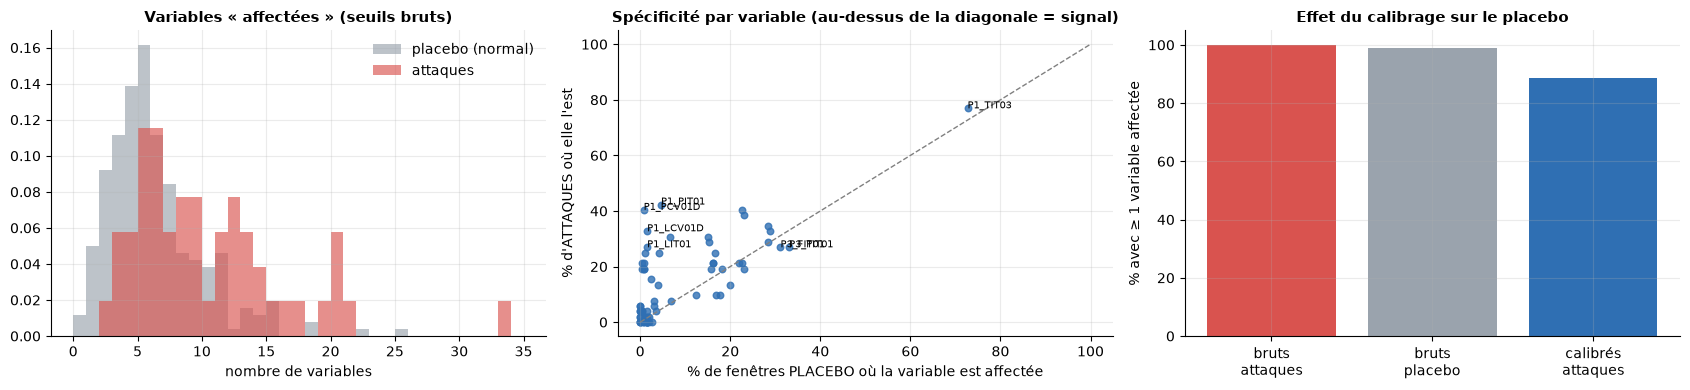

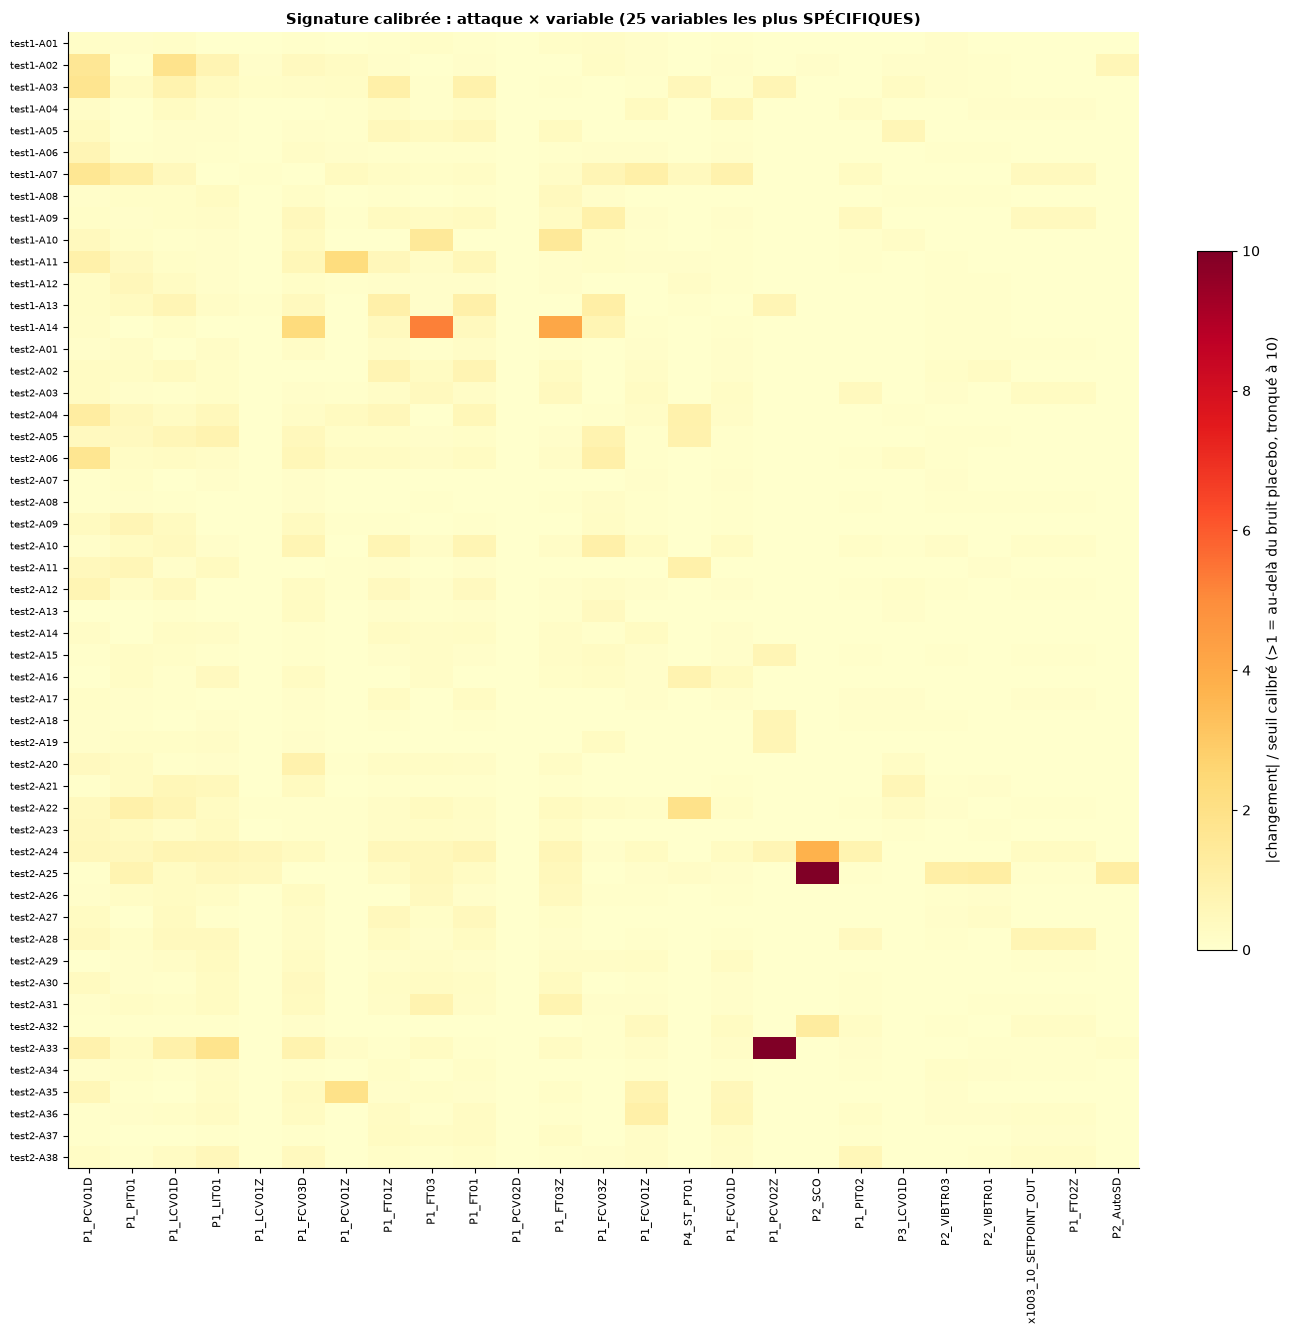

In [27]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
bins = range(0, int(max(n_raw_att.max(), n_raw_pl.max())) + 3)
ax[0].hist(n_raw_pl, bins=bins, alpha=.65, color=PALETTE["grey"], label="placebo (normal)", density=True); ax[0].hist(n_raw_att, bins=bins, alpha=.65, color=PALETTE["attack"], label="attaques", density=True)
ax[0].set_title("Variables « affectées » (seuils bruts)"); ax[0].set_xlabel("nombre de variables"); ax[0].legend(frameon=False)
ax[1].scatter(100 * fpr, 100 * att_rate, s=22, color=PALETTE["train"], alpha=.8); ax[1].plot([0, 100], [0, 100], "--", c="grey", lw=1)
for t in (att_rate - fpr).sort_values(ascending=False).head(4).index.tolist() + fpr.sort_values(ascending=False).head(3).index.tolist(): ax[1].annotate(t, (100 * fpr[t], 100 * att_rate[t]), fontsize=7)
ax[1].set_xlabel("% de fenêtres PLACEBO où la variable est affectée"); ax[1].set_ylabel("% d'ATTAQUES où elle l'est"); ax[1].set_title("Spécificité par variable (au-dessus de la diagonale = signal)")
ax[2].bar(["bruts\nattaques", "bruts\nplacebo", "calibrés\nattaques"], [100 * (n_raw_att > 0).mean(), 100 * (n_raw_pl > 0).mean(), 100 * (n_aff[valid] > 0).mean()], color=[PALETTE["attack"], PALETTE["grey"], PALETTE["train"]])
ax[2].set_ylabel("% avec ≥ 1 variable affectée"); ax[2].set_title("Effet du calibrage sur le placebo")
savefig("12_signature_placebo")

top = (att_rate - fpr).sort_values(ascending=False).head(25).index; EXC = (LVL.abs() / thr_l)
sub = EXC.loc[valid, top].clip(0, 10)
fig, ax = plt.subplots(figsize=(13, max(5, .22 * len(sub) + 2))); im = ax.imshow(sub, aspect="auto", cmap="YlOrRd", vmin=0, vmax=10); ax.grid(False)
ax.set_xticks(range(len(top))); ax.set_xticklabels(top, rotation=90, fontsize=8); ax.set_yticks(range(len(sub))); ax.set_yticklabels(sub.index, fontsize=7)
plt.colorbar(im, ax=ax, fraction=.03, label="|changement| / seuil calibré (>1 = au-delà du bruit placebo, tronqué à 10)"); ax.set_title("Signature calibrée : attaque × variable (25 variables les plus SPÉCIFIQUES)")
savefig("13_heatmap_attaques")

**Ce que le calibrage ne règle pas : les tests multiples.** Chaque variable a son seuil au 99ᵉ centile du placebo ; mais avec **66 variables à la fois**, une fenêtre normale a mécaniquement une probabilité non négligeable de dépasser *au moins un* seuil (jusqu'à ≈ 48 % si les variables étaient indépendantes). Dire « 46 attaques sur 52 ont une variable affectée » n'a de sens qu'à côté du taux obtenu sur des fenêtres normales **avec des seuils appris ailleurs**. On applique donc une validation croisée : seuils appris sur une moitié du placebo, appliqués à l'autre moitié et aux attaques. On en tire une **borne de détectabilité univariée** (AUC, taux de détection à 5 % de fausses alertes), qui servira de point de comparaison en Phase 2 : un modèle multivarié n'a d'intérêt que s'il fait mieux.

*Limite assumée :* la durée de chaque fenêtre est connue (on la prend égale à celle de l'attaque), ce qui rend cette borne **optimiste** par rapport à un détecteur en ligne.

In [28]:
from scipy.stats import mannwhitneyu
fold = np.random.default_rng(SEED).integers(0, 2, len(LVLp)); sc_pl = pd.Series(0.0, index=LVLp.index); sc_at = []
for f in (0, 1):
    other = fold == (1 - f); tl = np.maximum(LEVEL_Z, LVLp[other].abs().quantile(.99)); td = np.maximum(DYN_RATIO, DYNp[other].quantile(.99))   # seuils appris sur l'AUTRE moitié
    mine = fold == f; sc_pl[mine] = ((LVLp[mine].abs() > tl) | (DYNp[mine] > td)).sum(axis=1)
    sc_at.append(((LVL.abs() > tl) | (DYN > td)).where(valid, False).sum(axis=1))
sc_at = ((sc_at[0] + sc_at[1]) / 2)[valid].to_numpy(); sc_nl = sc_pl.to_numpy()
auc = mannwhitneyu(sc_at, sc_nl, alternative="greater").statistic / (len(sc_at) * len(sc_nl))
rb = np.random.default_rng(SEED); boots = [mannwhitneyu(rb.choice(sc_at, len(sc_at)), sc_nl, alternative="greater").statistic / (len(sc_at) * len(sc_nl)) for _ in range(300)]
ci = np.percentile(boots, [2.5, 97.5]); thr5 = np.quantile(sc_nl, .95); tpr5 = float((sc_at > thr5).mean())
null_rate, att_rate_cf = float((sc_nl > 0).mean()), float((sc_at > 0).mean())
display(pd.DataFrame({"fenêtres placebo (seuils appris ailleurs)": [len(sc_nl), null_rate, float(np.median(sc_nl))], "attaques": [len(sc_at), att_rate_cf, float(np.median(sc_at))]},
                     index=["effectif", "part avec ≥ 1 variable au-dessus du seuil", "variables au-dessus du seuil : médiane"]).round(3))
insight("Borne univariée", f"Validation croisée : {100*null_rate:.0f} % des fenêtres NORMALES dépassent au moins un seuil (bruit résiduel des 66 tests simultanés) contre {100*att_rate_cf:.0f} % des attaques. AUC (nombre de variables au-dessus du seuil) = {auc:.2f} [IC95 % bootstrap {ci[0]:.2f}–{ci[1]:.2f}] ; détection de {100*tpr5:.0f} % des attaques à ≈ 5 % de fausses alertes (fenêtres de durée connue : borne OPTIMISTE).")
insight("Borne univariée", "Lecture : plus l'AUC est loin de 1, plus la détection exige les RELATIONS entre variables et la dynamique, pas des seuils par variable. C'est la référence à battre par l'Autoencoder / le LSTM-AE ; si un modèle multivarié ne la dépasse pas, sa complexité n'est pas justifiée.")

,fenêtres placebo (seuils appris ailleurs),attaques
effectif,260.000,52.000
part avec ≥ 1 variable au-dessus du seuil,0.438,0.904
variables au-dessus du seuil : médiane,0.000,3.500


💡 [Borne univariée] Validation croisée : 44 % des fenêtres NORMALES dépassent au moins un seuil (bruit résiduel des 66 tests simultanés) contre 90 % des attaques. AUC (nombre de variables au-dessus du seuil) = 0.80 [IC95 % bootstrap 0.74–0.86] ; détection de 38 % des attaques à ≈ 5 % de fausses alertes (fenêtres de durée connue : borne OPTIMISTE).
💡 [Borne univariée] Lecture : plus l'AUC est loin de 1, plus la détection exige les RELATIONS entre variables et la dynamique, pas des seuils par variable. C'est la référence à battre par l'Autoencoder / le LSTM-AE ; si un modèle multivarié ne la dépasse pas, sa complexité n'est pas justifiée.


In [29]:
nv = int(valid.sum())
def top3(i):
    s = EXC.loc[i].sort_values(ascending=False).head(3); return ", ".join(f"{t} ({v:.1f}×)" for t, v in s.items() if np.isfinite(v))
rows = []
for k in ("test1", "test2"):
    for j, s in SEG[k].iterrows():
        i = f"{k}-A{j+1:02d}"
        rows.append({"id": i, "fichier": k, "début": s["début"], "fin": s["fin"], "durée_s": int(s["durée_s"]), "part_des_secondes_d_attaque_%": round(100 * s["durée_s"] / raw[k]["label"].sum(), 2),
                     "pré_fenêtre_valide": bool(valid[i]), "variables_affectées_brut": int(raw_aff_att.loc[i].sum()) if valid[i] else np.nan,
                     "variables_affectées_calibré": int(n_aff[i]) if valid[i] else np.nan, "top3_excès_vs_placebo": top3(i) if valid[i] else ""})
ATTACK_CAT = pd.DataFrame(rows).set_index("id")
ATTACK_CAT["signature"] = pd.cut(ATTACK_CAT["variables_affectées_calibré"], [-1, 0, 2, 1e9], labels=["aucune", "faible (1-2)", "forte (≥3)"]).astype(object).fillna("non évaluable")
ATTACK_CAT.to_csv(OUT_DIR / "attack_catalog.csv"); display(ATTACK_CAT.head(6)); display(ATTACK_CAT["signature"].value_counts().to_frame("attaques").T)

insight("Placebo", f"Avec les seuils BRUTS, {100*(n_raw_pl > 0).mean():.0f} % des fenêtres NORMALES ont au moins une variable « affectée » (médiane {n_raw_pl.median():.0f}, max {int(n_raw_pl.max())}) contre {100*(n_raw_att > 0).mean():.0f} % des attaques (médiane {n_raw_att.median():.0f}). " + ("Les seuils bruts ne sont donc PAS spécifiques : constater que « toutes les attaques ont une variable affectée » ne prouve rien tant que le placebo n'est pas comparé." if (n_raw_pl > 0).mean() > .3 else "Le placebo reste calme : les seuils bruts sont déjà assez spécifiques."))
nonspec = fpr[fpr > .10].sort_values(ascending=False)
if len(nonspec): insight("Placebo", f"{len(nonspec)} variable(s) sont « affectées » dans plus de 10 % des fenêtres NORMALES : {nonspec.head(6).round(2).to_dict()} → peu spécifiques (variables lisses/quantifiées/à tendance), à ne pas prendre pour des signatures d'attaque.")
n_cal = int((n_aff[valid] > 0).sum())
insight("Signature", f"Après calibrage sur le placebo : {n_cal}/{nv} attaques ont au moins une variable significativement affectée ; médiane {n_aff[valid].median():.0f} variable(s), max {int(n_aff.max())} ; {int((n_aff[valid] == 1).sum())} attaque(s) n'en affectent qu'UNE seule ; {nv - n_cal} sans signature univariée détectable (elles ne se verront que par les relations multivariées ou la dynamique). ATTENTION : 66 seuils simultanés produisent un bruit résiduel, mesuré par validation croisée ci-dessus ({100*null_rate:.0f} % des fenêtres normales dépassent au moins un seuil).")
spec = (att_rate - fpr).sort_values(ascending=False).head(5)
insight("Signature", "Variables les plus SPÉCIFIQUES (fréquence en attaque − fréquence en placebo) : " + ", ".join(f"{t} (+{100*v:.0f} pts)" for t, v in spec.items()) + ". Candidates du top-K d'explicabilité (F8) ; à comparer avec les variables désignées par l'Autoencoder en Phase 2.")
conc = {k: ATTACK_CAT[ATTACK_CAT.fichier == k]["durée_s"].nlargest(5).sum() / raw[k]["label"].sum() for k in ("test1", "test2")}
insight("Concentration", "Les 5 plus longues attaques représentent " + ", ".join(f"{100*v:.0f} % des secondes d'attaque de {k}" for k, v in conc.items()) + " : un F1 « par point » serait dominé par quelques attaques → métriques par événement (eTaPR) et rappel PAR ATTAQUE indispensables (F11).")
insight("Sévérité", "Le nombre de variables significativement affectées et leur excès par rapport au placebo fournissent une base empirique pour NORMAL/LOW/MEDIUM/HIGH/CRITICAL (F7) ; à valider sur le catalogue exporté `attack_catalog.csv`.")

,fichier,début,fin,durée_s,part_des_secondes_d_attaque_%,pré_fenêtre_valide,variables_affectées_brut,variables_affectées_calibré,top3_excès_vs_placebo,signature
id,,,,,,,,,,
test1-A01,test1,2022-08-12 16:25:04,2022-08-12 16:29:01,238,7.98,True,9,5,"P1_TIT03 (0.5×), P1_FCV03Z (0.2×), P1_FT03Z (0...",forte (≥3)
test1-A02,test1,2022-08-12 17:35:01,2022-08-12 17:38:19,199,6.68,True,12,4,"P1_LCV01D (1.9×), P1_PCV01D (1.6×), P1_LIT01 (...",forte (≥3)
test1-A03,test1,2022-08-12 18:32:17,2022-08-12 18:34:53,157,5.27,True,14,10,"P1_PCV01D (1.7×), P1_FT01Z (1.0×), P1_PP04D (1...",forte (≥3)
test1-A04,test1,2022-08-12 19:21:04,2022-08-12 19:23:48,165,5.54,True,12,6,"P1_FCV01D (0.6×), P3_LIT01 (0.5×), P1_TIT03 (0...",forte (≥3)
test1-A05,test1,2022-08-12 20:43:01,2022-08-12 20:45:42,162,5.43,True,6,2,"P2_SCST (0.9×), P3_LCV01D (0.6×), P4_HT_PO (0.6×)",faible (1-2)
test1-A06,test1,2022-08-12 21:36:01,2022-08-12 21:39:18,198,6.64,True,9,6,"P1_PP04D (1.0×), P1_PCV01D (0.7×), P1_TIT03 (0...",forte (≥3)


signature,forte (≥3),faible (1-2),aucune
attaques,30,16,6


💡 [Placebo] Avec les seuils BRUTS, 99 % des fenêtres NORMALES ont au moins une variable « affectée » (médiane 5, max 25) contre 100 % des attaques (médiane 8). Les seuils bruts ne sont donc PAS spécifiques : constater que « toutes les attaques ont une variable affectée » ne prouve rien tant que le placebo n'est pas comparé.
💡 [Placebo] 22 variable(s) sont « affectées » dans plus de 10 % des fenêtres NORMALES : {'P1_TIT03': 0.73, 'P3_PIT01': 0.33, 'P3_FIT01': 0.31, 'P4_HT_PO': 0.29, 'P3_LCV01D': 0.28, 'P1_PP04': 0.28} → peu spécifiques (variables lisses/quantifiées/à tendance), à ne pas prendre pour des signatures d'attaque.
💡 [Signature] Après calibrage sur le placebo : 46/52 attaques ont au moins une variable significativement affectée ; médiane 3 variable(s), max 25 ; 13 attaque(s) n'en affectent qu'UNE seule ; 6 sans signature univariée détectable (elles ne se verront que par les relations multivariées ou la dynamique). ATTENTION : 66 seuils simultanés produisent un bruit résiduel, 

## 10. Dérive naturelle entre jeux (train vs validation/test normaux)
**Pourquoi.** Les parties **normales** des fichiers de test ont-elles la même distribution que le train ? Si non, un modèle parfait en laboratoire produira des **faux positifs** en production : c'est exactement le problème que cible IndustrialGuard (F18, F19). Cette analyse crée aussi une **référence** : combien de drift existe *déjà* entre deux fichiers purement normaux (train vs train4) ?

Mesure : statistique de **Kolmogorov-Smirnov** (distance maximale entre fonctions de répartition ; 0 = identiques, 1 = disjointes). Avec des centaines de milliers de points, la p-value est toujours ~0 : on se fie à la **taille de l'effet** (`KS_THRESHOLD` = 0,15).

,train4 (normal),test1 (partie normale),test2 (partie normale)
% de variables avec KS > seuil,0.47,0.455,0.439


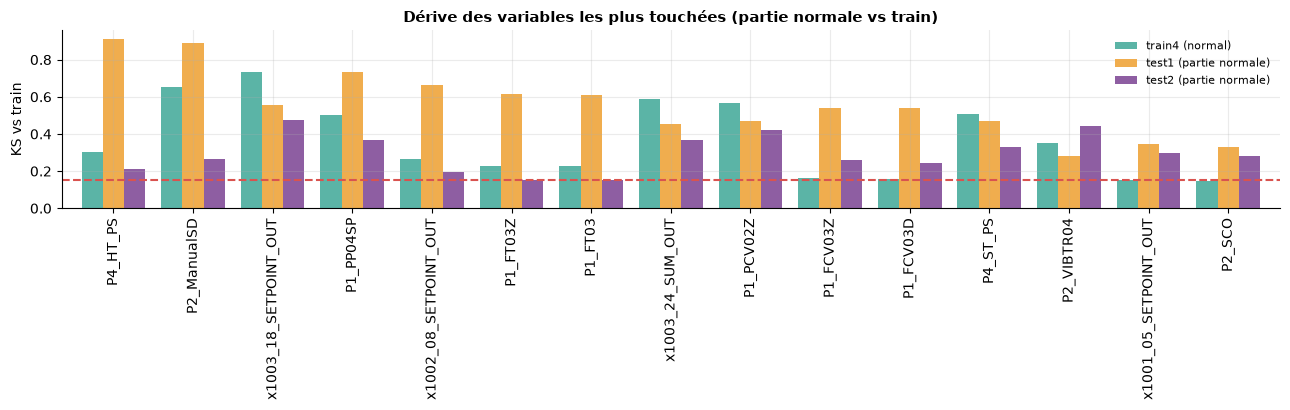

In [30]:
def normal_part(k): d = raw[k]; return d[d["label"] == 0] if "label" in d else d
REF = TR[FEATS_NC].sample(min(20000, len(TR)), random_state=SEED)
def ks_vs_ref(df):
    cur = df[FEATS_NC].sample(min(20000, len(df)), random_state=SEED)
    return pd.Series({c: stats.ks_2samp(REF[c].dropna(), cur[c].dropna()).statistic for c in FEATS_NC})
KS = pd.DataFrame({"train4 (normal)": ks_vs_ref(raw["train4"]), "test1 (partie normale)": ks_vs_ref(normal_part("test1")), "test2 (partie normale)": ks_vs_ref(normal_part("test2"))})
share = (KS > KS_THRESHOLD).mean().round(3); display(share.to_frame("% de variables avec KS > seuil").T)
top = KS.max(axis=1).sort_values(ascending=False).head(15).index
fig, ax = plt.subplots(figsize=(13, 4.2)); KS.loc[top].plot.bar(ax=ax, width=.8, color=[PALETTE["val_normal"], PALETTE["val"], PALETTE["test"]])
ax.axhline(KS_THRESHOLD, ls="--", c=PALETTE["attack"]); ax.set_ylabel("KS vs train"); ax.set_title("Dérive des variables les plus touchées (partie normale vs train)"); ax.legend(frameon=False, fontsize=8)
savefig("14_derive_naturelle")

In [31]:
base = share["train4 (normal)"]
for col in ("test1 (partie normale)", "test2 (partie normale)"):
    insight("Dérive", f"{col} : {share[col]:.0%} des variables dérivent (KS>{KS_THRESHOLD}) contre {base:.0%} pour train4 (référence normal↔normal).")
worst = KS.max(axis=1).sort_values(ascending=False).head(3)
insight("Dérive", "Variables les plus dérivantes : " + ", ".join(f"{t} (KS={v:.2f})" for t, v in worst.items()) + ".")
cross = KS.max(axis=1); session_specific = cross[KS["train4 (normal)"] > .5].index.tolist()
if base > .2:
    insight("Dérive", f"Dérive intra-normale MASSIVE : {base:.0%} des variables dérivent déjà entre deux fichiers purement normaux (train vs train4). Le « normal » change fortement d'une session à l'autre.")
    insight("Dérive", "Conséquence pour le Decision Engine (F21) : un drift seul NE DOIT JAMAIS déclencher un réentraînement. Il faut (1) calibrer les seuils de drift sur cette ligne de base, (2) confirmer par une dégradation mesurée du modèle, (3) alerter plutôt que réentraîner quand seul le drift est présent.")
    if session_specific: insight("Dérive", f"Variables à forte dérive de session (KS>0,5 train4 vs train) : {session_specific[:8]} — probablement des consignes/états propres à chaque session ; risque que le modèle apprenne « l'identité de la session » et sur-alerte sur un nouveau régime.")
elif share.max() > max(base, .05):
    insight("Dérive", "Dérive naturelle significative dans la partie normale des jeux de test → scénario réaliste de dégradation pour la démo du Decision Engine.")
else:
    insight("Dérive", "Peu de drift naturel : le scénario de dégradation de la démo devra être simulé (injection de drift contrôlé).")

💡 [Dérive] test1 (partie normale) : 46% des variables dérivent (KS>0.15) contre 47% pour train4 (référence normal↔normal).
💡 [Dérive] test2 (partie normale) : 44% des variables dérivent (KS>0.15) contre 47% pour train4 (référence normal↔normal).
💡 [Dérive] Variables les plus dérivantes : P4_HT_PS (KS=0.91), P2_ManualSD (KS=0.89), x1003_18_SETPOINT_OUT (KS=0.73).
💡 [Dérive] Dérive intra-normale MASSIVE : 47% des variables dérivent déjà entre deux fichiers purement normaux (train vs train4). Le « normal » change fortement d'une session à l'autre.
💡 [Dérive] Conséquence pour le Decision Engine (F21) : un drift seul NE DOIT JAMAIS déclencher un réentraînement. Il faut (1) calibrer les seuils de drift sur cette ligne de base, (2) confirmer par une dégradation mesurée du modèle, (3) alerter plutôt que réentraîner quand seul le drift est présent.
💡 [Dérive] Variables à forte dérive de session (KS>0,5 train4 vs train) : ['P1_PCV02Z', 'P1_PP04SP', 'P2_ManualSD', 'P4_ST_PS', 'x1003_18_SETPOINT_O

### 10.1 Matrice de similarité entre sessions
Part des variables dont la distribution diffère (KS > seuil) entre **chaque paire de sessions normales**. Une session proche de plusieurs autres est « représentative » ; une session isolée correspond à un régime à part. C'est ce qui dira si le train couvre assez de régimes pour les sessions de test.

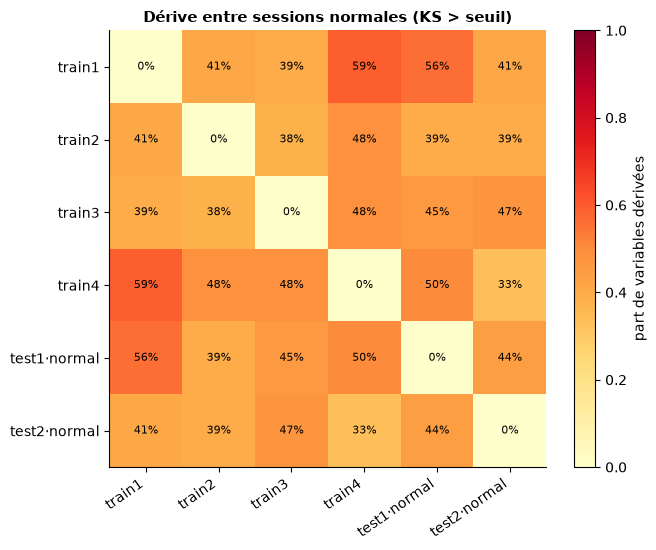

💡 [Sessions] Dérive moyenne entre deux sessions normales : 45% des variables (min 33%, max 59%).
💡 [Sessions] Session d'entraînement la plus proche : test1·normal ← train2 (39%), test2·normal ← train4 (33%). Si une session de test n'est proche d'aucune session train, le train ne couvre pas son régime → faux positifs attendus.


,train1,train2,train3,train4,test1·normal,test2·normal
P4_HT_PS,4.910000,3.590000,5.340000,4.400000,7.940000,3.640000
P2_ManualSD,12.080000,12.450000,12.220000,12.730000,12.930000,12.630000
x1003_18_SETPOINT_OUT,26.910000,26.090000,27.070000,25.190001,26.100000,25.420000
P1_PP04SP,27.980000,27.309999,27.920000,27.660000,27.490000,27.920000
x1002_08_SETPOINT_OUT,993.840027,1009.210022,1010.719971,1017.739990,951.080017,994.770020
P1_FT03Z,992.679993,1012.020020,1009.789978,1016.169983,957.020020,995.729980
P1_FT03,242.839996,251.809998,250.470001,254.289993,227.199997,244.179993
x1003_24_SUM_OUT,30.860001,29.910000,30.980000,29.059999,29.930000,29.520000


In [32]:
SESS = {"train1": raw["train1"], "train2": raw["train2"], "train3": raw["train3"], "train4": raw["train4"],
        "test1·normal": normal_part("test1"), "test2·normal": normal_part("test2")}
SMP = {k: v[FEATS_NC].sample(min(8000, len(v)), random_state=SEED) for k, v in SESS.items()}
names = list(SESS); M = pd.DataFrame(0.0, index=names, columns=names)
for i, a in enumerate(names):
    for b in names[i + 1:]:
        M.loc[a, b] = M.loc[b, a] = np.mean([stats.ks_2samp(SMP[a][c].dropna(), SMP[b][c].dropna()).statistic > KS_THRESHOLD for c in FEATS_NC])
fig, ax = plt.subplots(figsize=(6.8, 5.6)); im = ax.imshow(M, cmap="YlOrRd", vmin=0, vmax=1); ax.grid(False)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=35, ha="right"); ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
for i in range(len(names)):
    for j in range(len(names)): ax.text(j, i, f"{M.iloc[i, j]:.0%}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, fraction=.046, label="part de variables dérivées"); ax.set_title("Dérive entre sessions normales (KS > seuil)")
savefig("14b_similarite_sessions")
off = M.values[np.triu_indices(len(names), 1)]
insight("Sessions", f"Dérive moyenne entre deux sessions normales : {off.mean():.0%} des variables (min {off.min():.0%}, max {off.max():.0%}).")
nearest = {t: M.loc[t, ["train1", "train2", "train3", "train4"]].idxmin() for t in ("test1·normal", "test2·normal")}
insight("Sessions", "Session d'entraînement la plus proche : " + ", ".join(f"{t} ← {s} ({M.loc[t, s]:.0%})" for t, s in nearest.items()) + ". Si une session de test n'est proche d'aucune session train, le train ne couvre pas son régime → faux positifs attendus.")
fp = KS.max(axis=1).sort_values(ascending=False).head(8).index
display(pd.DataFrame({k: v[fp].median() for k, v in SESS.items()}).round(2))

**Lecture du tableau d'empreintes.** Pour les 8 variables les plus dérivantes, la médiane par session montre *comment* elles changent : un saut net d'une session à l'autre = consigne/régime opérateur ; une variation progressive = vieillissement ou dérive de procédé. Cette distinction guidera le Decision Engine (changement de régime ≠ dégradation).

### 10.2 Distance de chaque session au train (décalage de médiane en σ)
Le KS signale *qu'une distribution diffère* ; ici on mesure *de combien le niveau de fonctionnement a bougé* : pour chaque variable, |médiane de la session − médiane du train| / σ du train. C'est la grandeur la plus parlante pour qualifier un **changement de régime**.

In [33]:
mu_tr, sd_tr = TR[FEATS_NC].median(), TR[FEATS_NC].std().replace(0, np.nan)
shift = pd.DataFrame({k: ((v[FEATS_NC].median() - mu_tr) / sd_tr).abs() for k, v in SESS.items()})
sess_tab = pd.DataFrame({"décalage moyen (σ)": shift.mean(), "% variables > 1σ": 100 * (shift > 1).mean(), "% variables > 2σ": 100 * (shift > 2).mean(), "variable la plus décalée": shift.idxmax()}).round(2)
display(sess_tab)
eff = sess_tab["décalage moyen (σ)"].drop(["train1", "train2", "train3"])
worst = eff.idxmax()
insight("Taille d'effet", f"Au sens du KS, {100*np.mean([M.loc[a, b] for a in names for b in names if a < b]):.0f} % des variables « dérivent » entre deux sessions normales ; mais le décalage de médiane entre une session normale et le train n'est que de {eff.mean():.2f} σ en moyenne (max {eff.max():.2f} σ), avec au plus {sess_tab.loc[eff.index, '% variables > 1σ'].max():.0f} % des variables décalées de plus de 1σ. La dérive est SYSTÉMATIQUE mais d'amplitude MODÉRÉE : le Decision Engine doit s'appuyer sur une taille d'effet calibrée sur cette ligne de base, pas sur un test de significativité seul (le KS signale un simple changement de consigne de 1 à 2 %).")
insight("Sessions", f"Session la plus éloignée du train (hors train1-3) : {worst} (décalage moyen {sess_tab.loc[worst, 'décalage moyen (σ)']:.2f} σ, {sess_tab.loc[worst, '% variables > 1σ']:.0f} % des variables à plus de 1σ).")
insight("Sessions", "Si la session de VALIDATION (test1·normal) est la plus atypique, un seuil réglé dessus risque de ne pas se transférer au test final → on comparera plusieurs protocoles de choix du seuil (hypothèse H6, Phase 2)." if worst.startswith("test1") else "La session de validation (test1·normal) n'est pas la plus atypique : le risque de transfert du seuil vers le test est moindre, à confirmer en Phase 2 (H6).")

,décalage moyen (σ),% variables > 1σ,% variables > 2σ,variable la plus décalée
train1,0.17,1.52,0.00,P1_PCV02Z
train2,0.15,3.03,0.00,P1_PP04SP
train3,0.18,1.52,0.00,P4_ST_PS
train4,0.28,4.55,1.52,x1003_18_SETPOINT_OUT
test1·normal,0.31,9.09,0.00,x1002_08_SETPOINT_OUT
test2·normal,0.27,6.06,0.00,x1003_18_SETPOINT_OUT


💡 [Taille d'effet] Au sens du KS, 45 % des variables « dérivent » entre deux sessions normales ; mais le décalage de médiane entre une session normale et le train n'est que de 0.29 σ en moyenne (max 0.31 σ), avec au plus 9 % des variables décalées de plus de 1σ. La dérive est SYSTÉMATIQUE mais d'amplitude MODÉRÉE : le Decision Engine doit s'appuyer sur une taille d'effet calibrée sur cette ligne de base, pas sur un test de significativité seul (le KS signale un simple changement de consigne de 1 à 2 %).
💡 [Sessions] Session la plus éloignée du train (hors train1-3) : test1·normal (décalage moyen 0.31 σ, 9 % des variables à plus de 1σ).
💡 [Sessions] Si la session de VALIDATION (test1·normal) est la plus atypique, un seuil réglé dessus risque de ne pas se transférer au test final → on comparera plusieurs protocoles de choix du seuil (hypothèse H6, Phase 2).


## 11. Qualité des données (F1)
**Pourquoi.** Cinq contrôles imposés par le cahier des charges : valeurs manquantes · doublons · valeurs aberrantes · continuité temporelle · colonnes constantes. Les résultats alimentent les **décisions** de la section 12.

In [34]:
def quality(df, name):
    cols, ts = sensor_cols(df), df["timestamp"]; dt = ts.diff().dt.total_seconds().dropna(); gaps = dt[dt > FREQ_S]
    x = df[cols]
    return {"fichier": name, "lignes": len(df), "trié": bool(ts.is_monotonic_increasing), "timestamps_dupliqués": int(ts.duplicated().sum()),
            "lignes_dupliquées": int(df.drop(columns="timestamp").duplicated().sum()), "cellules_NaN": int(x.isna().sum().sum()),
            "colonnes_constantes": int(sum(x[c].nunique() <= 1 for c in cols)), "trous": len(gaps), "plus_grand_trou_s": float(gaps.max()) if len(gaps) else 0.0,
            "secondes_manquantes": float((gaps - FREQ_S).sum())}
QUAL = pd.DataFrame([quality(v, k) for k, v in raw.items()]).set_index("fichier")
QUAL.to_json(REPORT_DIR / "data_quality.json", orient="index", indent=2); QUAL

,lignes,trié,timestamps_dupliqués,lignes_dupliquées,cellules_NaN,colonnes_constantes,trous,plus_grand_trou_s,secondes_manquantes
fichier,,,,,,,,,
train1,280800,True,0,0,0,20,0,0.0,0.0
train2,291600,True,0,0,0,20,0,0.0,0.0
train3,126000,True,0,0,0,22,0,0.0,0.0
train4,198000,True,0,0,0,20,0,0.0,0.0
test1,54000,True,0,0,0,27,0,0.0,0.0
test2,230400,True,0,0,0,18,0,0.0,0.0


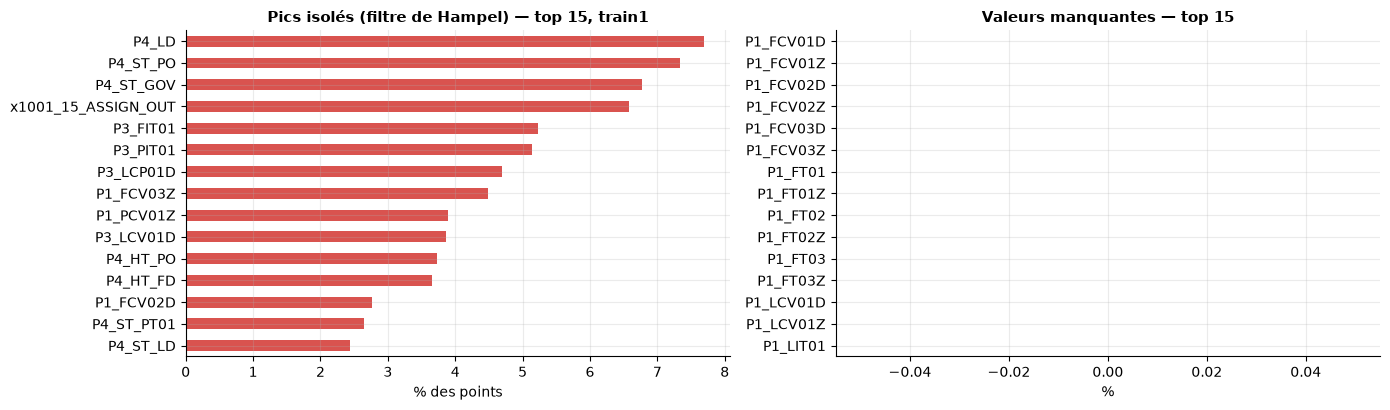

💡 [Qualité] Manquants : 0 cellules ; doublons de timestamp : 0 ; trous : 0 (0 s) ; colonnes constantes : 27.
💡 [Aberrants] Pics isolés (Hampel, fenêtre 61 s) : médiane 0.029 % des points par variable ; maximum P4_LD (7.69 %). Certaines variables sont très « piquées » : à surveiller, car un modèle sensible à l'erreur quadratique réagira à ces pics.
💡 [Aberrants] Le critère MAD global de la version précédente est abandonné : il classait comme « aberrantes » des variables simplement multimodales (vanne ouverte/fermée), ce qui n'a pas de sens physique. Aucune suppression d'aberrants n'est faite sur val/test (elle masquerait des attaques) ; seule la winsorisation du train (D8) s'applique.


In [35]:
nan_ratio = TR[FEATS_NC].isna().mean().sort_values(ascending=False)

def hampel_spikes(df, cols, window=61, k=6.0, min_amp=.25):
    # Pic = écart à la médiane LOCALE > k·MAD local ET > min_amp·σ global (ignore les signaux en escalier / bimodaux)
    x = df[cols].astype("float64"); m = x.rolling(window, center=True, min_periods=window // 2).median()
    dev = (x - m).abs(); mad = dev.rolling(window, center=True, min_periods=window // 2).median()
    return ((dev > k * 1.4826 * mad) & (dev > min_amp * x.std().replace(0, np.nan))).mean()
SPK = hampel_spikes(raw["train1"].iloc[:200_000], CONT).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
SPK.head(15)[::-1].mul(100).plot.barh(ax=ax[0], color=PALETTE["attack"]); ax[0].set_title("Pics isolés (filtre de Hampel) — top 15, train1"); ax[0].set_xlabel("% des points")
nan_ratio.head(15)[::-1].mul(100).plot.barh(ax=ax[1], color=PALETTE["val"]); ax[1].set_title("Valeurs manquantes — top 15"); ax[1].set_xlabel("%")
savefig("15_qualite")
tn = int(QUAL["cellules_NaN"].sum()); td = int(QUAL["timestamps_dupliqués"].sum()); tg = float(QUAL["secondes_manquantes"].sum())
insight("Qualité", f"Manquants : {tn:,} cellules ; doublons de timestamp : {td} ; trous : {int(QUAL['trous'].sum())} ({tg:,.0f} s) ; colonnes constantes : {int(QUAL['colonnes_constantes'].max())}.")
insight("Aberrants", f"Pics isolés (Hampel, fenêtre 61 s) : médiane {100*SPK.median():.3f} % des points par variable ; maximum {SPK.index[0]} ({100*SPK.iloc[0]:.2f} %). " + ("Les pics sont rares : ce sont de vrais événements ponctuels (capteur ou procédé), pas du bruit généralisé." if SPK.iloc[0] < .01 else "Certaines variables sont très « piquées » : à surveiller, car un modèle sensible à l'erreur quadratique réagira à ces pics."))
insight("Aberrants", "Le critère MAD global de la version précédente est abandonné : il classait comme « aberrantes » des variables simplement multimodales (vanne ouverte/fermée), ce qui n'a pas de sens physique. Aucune suppression d'aberrants n'est faite sur val/test (elle masquerait des attaques) ; seule la winsorisation du train (D8) s'applique.")

### 11.2 Variables constantes sur le train : sont-elles *vraiment* inutiles ?
Une variable figée à l'entraînement n'apporte aucune information **au modèle**… mais si elle **bouge pendant les tests**, ce changement est un signal d'anomalie évident (état de pompe, mode, commande jamais vus). La jeter perdrait cette information ; la normaliser (écart-type = 0) est impossible.

**Approche retenue :** retirer ces variables du modèle numérique **et** les surveiller par une **couche de règles** (« valeur ≠ valeur d'entraînement → alerte »). Cela répond aussi à F17 (*nouvelles valeurs inattendues*).

In [36]:
const_tags = [c for c in all_tags if nun[c] == 1]
v0 = TR[const_tags].iloc[0]
def share_diff(df): return (df[const_tags] != v0).mean()
CT = pd.DataFrame({"train4 (normal)": share_diff(raw["train4"]),
                   "test1 hors attaque": share_diff(raw["test1"][raw["test1"].label == 0]), "test1 en attaque": share_diff(raw["test1"][raw["test1"].label == 1]),
                   "test2 hors attaque": share_diff(raw["test2"][raw["test2"].label == 0]), "test2 en attaque": share_diff(raw["test2"][raw["test2"].label == 1])})
CT.insert(0, "valeur_train", v0)
moved = CT[(CT.drop(columns="valeur_train") > 0).any(axis=1)]
display((moved.drop(columns="valeur_train") * 100).round(2).assign(valeur_train=moved["valeur_train"]))
RULE_TAGS = {c: float(v0[c]) for c in const_tags}
att_only = moved[(moved[["test1 en attaque", "test2 en attaque"]].max(axis=1) > 0) & (moved[["train4 (normal)", "test1 hors attaque", "test2 hors attaque"]].max(axis=1) == 0)]
touch, delays = {}, []
for k in ("test1", "test2"):
    d = raw[k]
    for j, s in SEG[k].iterrows():
        a, b = int(s.i0), int(s.i1) + 1
        hit = {t: (d[t].iloc[a:b] != v0[t]).to_numpy() for t in att_only.index}
        hit = {t: m for t, m in hit.items() if m.any()}
        if hit: touch[f"{k}-A{j+1:02d}"] = list(hit); delays.append(min(int(np.argmax(m)) for m in hit.values()))
n_att = len(SEG["test1"]) + len(SEG["test2"])
insight("Constantes", f"{len(const_tags)} variables constantes sur le train ; {len(moved)} d'entre elles changent de valeur dans au moins un autre jeu.")
if len(att_only):
    insight("Constantes", f"{len(att_only)} variable(s) constante(s) à l'entraînement ne changent, dans les sessions analysées, QUE pendant des attaques : {att_only.index.tolist()}. Précision de 100 % sur ces sessions, mais COUVERTURE limitée : {len(touch)}/{n_att} attaques ({100*len(touch)/n_att:.0f} %), avec un délai médian de {np.median(delays) if delays else float('nan'):.0f} s après le début de l'attaque (souvent un effet, pas une cause).")
    insight("Constantes", "À confirmer sur d'autres sessions et scénarios : ce n'est PAS une preuve universelle d'attaque. Rôle retenu : couche de règles COMPLÉMENTAIRE (alerte à haute précision), jamais substitut du modèle.")
else: insight("Constantes", "Aucune constante ne change exclusivement pendant les attaques ; si certaines changent aussi hors attaque, ce sont des changements de régime (signal faible, pas une détection).")

,train4 (normal),test1 hors attaque,test1 en attaque,test2 hors attaque,test2 en attaque,valeur_train
P2_Emerg,0.0,0.0,0.0,0.0,1.12,0.0
P2_OnOff,0.0,0.0,0.0,0.0,1.37,1.0


💡 [Constantes] 20 variables constantes sur le train ; 2 d'entre elles changent de valeur dans au moins un autre jeu.
💡 [Constantes] 2 variable(s) constante(s) à l'entraînement ne changent, dans les sessions analysées, QUE pendant des attaques : ['P2_Emerg', 'P2_OnOff']. Précision de 100 % sur ces sessions, mais COUVERTURE limitée : 2/52 attaques (4 %), avec un délai médian de 27 s après le début de l'attaque (souvent un effet, pas une cause).
💡 [Constantes] À confirmer sur d'autres sessions et scénarios : ce n'est PAS une preuve universelle d'attaque. Rôle retenu : couche de règles COMPLÉMENTAIRE (alerte à haute précision), jamais substitut du modèle.


## 12. Décisions de prétraitement (et leur preuve)
Chaque décision est reliée à une observation des sections précédentes. Cette traçabilité sera reprise dans le rapport de projet.

| # | Décision | Justification (preuve) | Paramètre |
|---|---|---|---|
| D1 | HAI 86 tags, pas HAIEnd | le cahier des charges cible l'ICS au niveau process ; HAIEnd (225) augmente le coût sans objectif MLOps | `VERSION_TAG` |
| D2 | **Deux protocoles produits** : `sessions` (train1-3 / train4 / test1 / test2) et `chrono` (train1 + train2 sans 10 h / 10 h / test1 / test2 ; train3+4 = flux de production) | aucun chevauchement (§4.2) mais le découpage `sessions` n'est PAS chronologique (§4.3) : les deux répondent à des questions différentes | `split_frames` |
| D3 | Seuil choisi sur `val` (test1), évaluation finale sur `test` (test2) | le test final ne doit jamais influencer une décision | — |
| D4 | **Trous ≤ 5 s comblés** (ffill) ; trous > 5 s laissés comme trous | on ne fabrique pas de données industrielles sur de longues périodes (§7.1) | `MAX_FFILL_S` |
| D5 | Doublons de timestamp supprimés (on garde le 1er) | un instant = une mesure (§11) | — |
| D6 | Colonnes constantes exclues | aucune information, variance nulle (§5) | — |
| D7 | **Z-score ajusté sur le train seul** | échelles très hétérogènes (§6) ; l'ajustement sur val/test serait une fuite | `StandardScaler` |
| D8 | Winsorisation à ±`TRAIN_CLIP_SIGMA` σ **sur le train uniquement** | évite que quelques points extrêmes tirent l'apprentissage ; jamais sur val/test car cela masquerait les attaques (§9, §11) | `TRAIN_CLIP_SIGMA` |
| D9 | Variables corrélées **conservées** | la redondance fait partie de la structure normale apprise par l'AE (§8.1) | `DROP_CORRELATED` |
| D10 | Variables binaires/discrètes conservées telles quelles (revue en Phase 2) | peu nombreuses, informatives sur les modes (§5) | — |
| D11 | Stats de référence du train sauvegardées | base du Data Drift (F18) (§10) | — |
| D12 | **Constantes du train : hors modèle mais surveillées par règles** (`constant_rules.json`) | une constante qui bouge en test est un signal d'anomalie (§11.2) | — |
| D13 | **Labels alignés par position** quand leurs timestamps sont tronqués (+ contrôles bloquants) | `label-test2.csv` : timestamps à la minute (§4) | `align_labels` |
| D14 | Outliers mesurés par filtre de Hampel, jamais supprimés sur val/test | MAD global confond multimodalité et aberrants (§11) | — |
| D15 | **Sélection stricte de la version des fichiers** (erreur si absente ou ambiguë, aucun repli) | un repli silencieux vers une autre version de HAI fausserait toute la chaîne | `find_hai_files` |
| D16 | **Un label manquant n'est jamais converti en « normal »** ; label d'une ligne insérée conservé seulement si ses voisins s'accordent | risque de fausser les métriques de détection | `align_labels`, `clean_file` |
| D17 | Alignement positionnel **contrôlé** (tri, lignes/minute, 100 %) puis **recoupé à la seconde** avec le catalogue officiel | l'ordre intra-minute n'est pas vérifiable autrement (§9.1b) | `crosscheck` |
| D18 | Variables instables (|z| > `UNSTABLE_Z` sur données normales) **signalées** ; politique `UNSTABLE_POLICY` | à trancher par ablation (H4) | `UNSTABLE_POLICY` |

In [37]:
decisions = pd.DataFrame([
    ("D2", "Protocoles de découpage", "sessions (défaut) + chrono"), ("D4", "Comblement des petits trous", f"≤ {MAX_FFILL_S} s"),
    ("D6/D12", "Constantes : hors modèle + règles", f"{len(tags[tags.nature == 'constante'])} variables → constant_rules.json"),
    ("D7", "Normalisation", "StandardScaler (train seul)"), ("D8", "Winsorisation train (hypothèse H2)", f"±{TRAIN_CLIP_SIGMA} σ"), ("D18", "Variables instables", f"{UNSTABLE_POLICY} (|z| > {UNSTABLE_Z})"),
    ("D9", "Suppression des variables corrélées", "non" if not DROP_CORRELATED else f"oui (|corr|>{CORR_THRESHOLD})")], columns=["id", "décision", "valeur appliquée"]).set_index("id"); decisions

,décision,valeur appliquée
id,,
D2,Protocoles de découpage,sessions (défaut) + chrono
D4,Comblement des petits trous,≤ 5 s
D6/D12,Constantes : hors modèle + règles,20 variables → constant_rules.json
D7,Normalisation,StandardScaler (train seul)
D8,Winsorisation train (hypothèse H2),±10 σ
D18,Variables instables,keep_and_flag (|z| > 50)
D9,Suppression des variables corrélées,non


## 13. Nettoyage, protocoles de découpage et normalisation
Application des décisions D2 à D8 et D15 à D18. Les fonctions viennent de `src/data/prep.py` : **le notebook, le pipeline DVC et (Phase 3) l'API utilisent le même code**, ce qui supprime tout risque de divergence entre entraînement et production.

**Règle anti-fuite :** tout ce qui est *appris* (colonnes retenues, moyenne/écart-type, bornes de winsorisation) vient **uniquement du train** de chaque protocole.

In [38]:
clean = {k: clean_file(v, FREQ_S, MAX_FFILL_S) for k, v in raw.items()}
cl = pd.DataFrame({k: {"avant": len(raw[k]), "après": len(clean[k]), "lignes retirées": len(raw[k]) - len(clean[k]), "lignes insérées conservées": clean[k].attrs.get("inserted_kept", 0),
                       "% retiré": round(100 * (1 - len(clean[k]) / len(raw[k])), 4)} for k in raw}).T
display(cl)
for k in raw:
    gate(f"nettoyage {k} : lignes conservées", len(clean[k]) >= .99 * len(raw[k]), f"{len(clean[k]):,}/{len(raw[k]):,} lignes ({100*len(clean[k])/len(raw[k]):.3f} %)")
    if "label" in raw[k]:
        r0, r1 = raw[k]["label"].mean(), clean[k]["label"].mean()
        gate(f"nettoyage {k} : taux d'attaque préservé", abs(r1 - r0) <= .02 * max(r0, 1e-9), f"{100*r0:.3f} % → {100*r1:.3f} %")
clean, EMB = apply_embargo(clean, EMBARGO_S)
if EMB: display(pd.DataFrame(EMB)); insight("Purge", f"{len(EMB)} frontière(s) CONTIGUË(S) purgée(s) de {EMBARGO_S} s côté apprentissage : " + "; ".join(f"{e['fichier']} ({e['côté']}, {e['raison']})" for e in EMB) + ". L'état du procédé se prolonge d'un fichier à l'autre ; sans purge, les premières minutes d'apprentissage prolongeraient la fin d'un jeu de validation/test.")
insight("Nettoyage", f"{int(cl['lignes retirées'].sum())} lignes retirées, {int(cl['lignes insérées conservées'].sum())} insérées (comblement ≤ {MAX_FFILL_S} s) sur {int(cl['avant'].sum()):,} : les données HAI sont déjà régulières, le nettoyage est essentiellement une vérification.")

,avant,après,lignes retirées,lignes insérées conservées,% retiré
train1,280800.0,280800.0,0.0,0.0,0.0
train2,291600.0,291600.0,0.0,0.0,0.0
train3,126000.0,126000.0,0.0,0.0,0.0
train4,198000.0,198000.0,0.0,0.0,0.0
test1,54000.0,54000.0,0.0,0.0,0.0
test2,230400.0,230400.0,0.0,0.0,0.0


✔ nettoyage train1 : lignes conservées — 280,800/280,800 lignes (100.000 %)
✔ nettoyage train2 : lignes conservées — 291,600/291,600 lignes (100.000 %)
✔ nettoyage train3 : lignes conservées — 126,000/126,000 lignes (100.000 %)
✔ nettoyage train4 : lignes conservées — 198,000/198,000 lignes (100.000 %)
✔ nettoyage test1 : lignes conservées — 54,000/54,000 lignes (100.000 %)
✔ nettoyage test1 : taux d'attaque préservé — 5.520 % → 5.520 %
✔ nettoyage test2 : lignes conservées — 230,400/230,400 lignes (100.000 %)
✔ nettoyage test2 : taux d'attaque préservé — 3.647 % → 3.647 %


,fichier,côté,lignes_retirées,raison
0,train2,début,600,contigu à la fin de test1
1,train3,début,600,contigu à la fin de test2


💡 [Purge] 2 frontière(s) CONTIGUË(S) purgée(s) de 600 s côté apprentissage : train2 (début, contigu à la fin de test1); train3 (début, contigu à la fin de test2). L'état du procédé se prolonge d'un fichier à l'autre ; sans purge, les premières minutes d'apprentissage prolongeraient la fin d'un jeu de validation/test.
💡 [Nettoyage] 0 lignes retirées, 0 insérées (comblement ≤ 5 s) sur 1,180,800 : les données HAI sont déjà régulières, le nettoyage est essentiellement une vérification.


In [39]:
EXCL = list(EXCLUDE_COLUMNS) + (sorted(set(high["b"])) if DROP_CORRELATED else [])
PROTOCOLS, FRAMES = {}, {}
for name in ("sessions", "chrono"):
    FRAMES[name] = split_frames(clean, name, HOLDOUT_H, EMBARGO_S)
    PROTOCOLS[name] = prepare_protocol(name, FRAMES[name], clip_sigma=TRAIN_CLIP_SIGMA, exclude=EXCL, unstable_z=UNSTABLE_Z, unstable_policy=UNSTABLE_POLICY)
P = PROTOCOLS[PRIMARY_PROTOCOL]; feats, scaler, splits, dropped = P.feats, P.scaler, P.splits, P.dropped
tab = pd.concat({n: pd.DataFrame({k: {"lignes": len(v), "durée_h": round(len(v) / 3600, 1), "début": v.timestamp.min(), "fin": v.timestamp.max(),
                                       "% attaque": round(100 * v["label"].mean(), 2) if "label" in v else 0.0} for k, v in p.splits.items()}).T for n, p in PROTOCOLS.items()})
display(tab)
for n, p in PROTOCOLS.items(): print(f"[{n}] {len(p.feats)} variables retenues ; {len(p.dropped)} retirées")

lignes durée_h                début                  fin  \
sessions train       697200   193.7  2022-08-04 18:00:01  2022-08-21 03:00:00   
         val_normal  198000    55.0  2022-08-22 17:00:01  2022-08-25 00:00:00   
         val          54000    15.0  2022-08-12 16:00:01  2022-08-13 07:00:00   
         test        230400    64.0  2022-08-17 00:00:01  2022-08-19 16:00:00   
chrono   train       535800   148.8  2022-08-04 18:00:01  2022-08-16 06:00:00   
         val_normal   35400     9.8  2022-08-16 06:10:01  2022-08-16 16:00:00   
         val          54000    15.0  2022-08-12 16:00:01  2022-08-13 07:00:00   
         test        230400    64.0  2022-08-17 00:00:01  2022-08-19 16:00:00   
         stream      323400    89.8  2022-08-19 16:10:01  2022-08-25 00:00:00   

                    % attaque  
sessions train            0.0  
         val_normal       0.0  
         val             5.52  
         test            3.65  
chrono   train            0.0  
         val_normal       0.0  
         val             5.52  
         test            3.65  
         stream           0.0

[sessions] 66 variables retenues ; 20 retirées
[chrono] 66 variables retenues ; 20 retirées


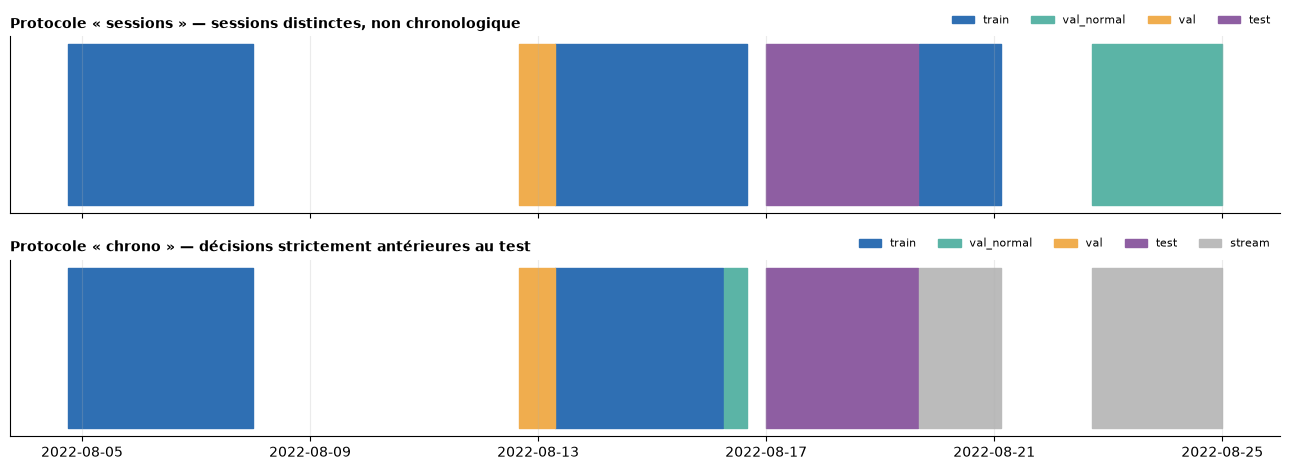

In [40]:
fig, axes = plt.subplots(2, 1, figsize=(13, 4.8), sharex=True)
for ax, (name, p) in zip(axes, PROTOCOLS.items()):
    for k, v in p.splits.items():
        ts = v["timestamp"]; brk = np.flatnonzero(ts.diff().dt.total_seconds().to_numpy() > 3600); starts, ends = np.r_[0, brk], np.r_[brk - 1, len(ts) - 1]
        for a, b in zip(starts, ends):
            s, e = mdates.date2num(ts.iloc[a]), mdates.date2num(ts.iloc[b]); ax.broken_barh([(s, max(e - s, .02))], (0, 1), color=PALETTE.get(k, "#bbbbbb"))
    ax.set_yticks([]); ax.xaxis_date(); ax.set_title(f"Protocole « {name} »" + (" — sessions distinctes, non chronologique" if name == "sessions" else " — décisions strictement antérieures au test"), loc="left", fontsize=10)
    ax.legend(handles=[Patch(color=PALETTE.get(k, "#bbbbbb"), label=k) for k in p.splits], ncol=5, frameon=False, fontsize=8, loc="lower right", bbox_to_anchor=(1, 1.0))
savefig("16_protocoles")

### 13.1 Stabilité de la normalisation
Un écart-type d'entraînement minuscule transforme une variation banale en *z-score* gigantesque : sur des données **normales**, cela fabrique des faux positifs. On regarde donc le |z| maximal sur `val_normal` (aucune attaque dedans).

In [41]:
print("Plus petits écarts-types du train (variables retenues) :"); display(P.ref_stats["std"].sort_values().head(5).to_frame("std").T)
zv = pd.Series(np.abs(scaler.transform(FRAMES[PRIMARY_PROTOCOL]["val_normal"][feats])).max(axis=0), index=feats).sort_values(ascending=False)
print("|z| maximal sur val_normal (données NORMALES) :"); display(zv.head(8).round(1).to_frame("max|z|").T)
unst = list(P.unstable)
if unst:
    SESS_RAW = {**{k: raw[k] for k in ("train1", "train2", "train3", "train4")}, "test1·normal": raw["test1"][raw["test1"].label == 0], "test2·normal": raw["test2"][raw["test2"].label == 0]}
    insp = pd.concat({v: pd.DataFrame({s: d[v].describe(percentiles=[.5])[["min", "50%", "max", "std"]] for s, d in SESS_RAW.items()}).T for v in unst[:5]}); display(insp.round(3))
    for v in unst[:5]:
        d = FRAMES[PRIMARY_PROTOCOL]["train"][v]; share = float((d == d.median()).mean())
        if share > .95:
            insight("Stabilité", f"{v} : |z| max = {P.unstable[v]:.0f} sur données normales. {100*share:.2f} % des points du train valent exactement {d.median():.3g} (σ = {d.std():.3f}) : variable à ÉVÉNEMENTS RARES (valeur « de repos » + excursions). Son z-score n'a pas de sens stable ; elle encode un événement, pas un niveau. Une règle de bande bâtie sur train+val_normal serait trompeuse (les excursions normales de test2 vont plus loin) → à traiter comme variable d'événement (indicateur « ≠ repos ») : hypothèse H4.")
        else:
            insight("Stabilité", f"{v} : |z| max = {P.unstable[v]:.0f} sur données normales ; variable continue à variance faible, à inspecter.")
    insight("Stabilité", f"Politique appliquée : « {UNSTABLE_POLICY} » (hypothèse H4 à trancher par ablation en Phase 2).")
else:
    insight("Stabilité", f"Aucune variable ne dépasse |z|={UNSTABLE_Z} sur val_normal : normalisation stable." if UNSTABLE_POLICY == "keep_and_flag" else "Aucune variable instable (ou déjà retirée par la politique « rule »).")
trn_ = FRAMES[PRIMARY_PROTOCOL]["train"]; mode_share = pd.Series({c: float((trn_[c] == trn_[c].median()).mean()) for c in feats})
rare = pd.DataFrame({"% au repos": 100 * mode_share[mode_share > .9], "σ train": P.ref_stats.loc[mode_share[mode_share > .9].index, "std"]}).sort_values("% au repos", ascending=False)
small = P.ref_stats["std"].nsmallest(5)
if len(rare): display(rare.round(4)); insight("Quasi-constantes", f"Famille 1 — variables à ÉVÉNEMENTS RARES (> 90 % du temps à leur valeur médiane) : {rare.index.tolist()[:8]}. Le z-score n'y décrit pas un niveau mais un événement.")
clip_small = sum(P.clip_stats["top_vars"].get(t, 0) for t in small.index); share_small = clip_small / max(P.clip_stats["total"], 1)
tiny = small[small < .01]
insight("Quasi-constantes", "Famille 2 — variables à plus faible σ : " + ", ".join(f"{t} (σ={v:.4f}, {P.clip_stats['top_vars'].get(t, 0):,} écrêtées)" for t, v in small.items()) + f". {100*share_small:.0f} % des valeurs écrêtées appartiennent à ces 5 variables" + (f" ; {len(tiny)} ont un σ inférieur à 0,01 (bruit de mesure de l'ordre du millième) : toute fluctuation banale y devient un grand z-score." if len(tiny) else ".") + " Les deux familles sont à comparer en Phase 2 (H4) : garder / indicateur d'événement / plancher d'échelle / exclure.")
cs = P.clip_stats
insight("Winsorisation", f"{cs['total']:,} valeurs du train ({cs['share_pct']:.4f} %) ramenées à ±{TRAIN_CLIP_SIGMA}σ ; variables les plus concernées : {list(cs['top_vars'].items())[:4]}. Le modèle apprend sur des valeurs plafonnées alors que val/test gardent leurs extrêmes (volontaire : ils signalent des anomalies) ; l'effet réel sur la détection est une HYPOTHÈSE (H2) à tester par ablation, pas un acquis.")

Plus petits écarts-types du train (variables retenues) :


,P4_ST_FD,P4_HT_FD,P2_24Vdc,P1_PCV02D,x1001_05_SETPOINT_OUT
std,0.001645,0.00208,0.003458,0.031168,0.042328


|z| maximal sur val_normal (données NORMALES) :


,P1_PCV02D,P1_PCV02Z,P1_FT01,P4_HT_FD,P1_FT01Z,P4_ST_FD,P1_PIT01,P4_ST_PT01
max|z|,93.199997,17.9,16.0,13.7,13.5,11.8,9.0,8.7


min   50%     max    std
P1_PCV02D train1        12.0  12.0  16.448  0.038
          train2        12.0  12.0  17.174  0.031
          train3        12.0  12.0  12.000  0.000
          train4        12.0  12.0  14.906  0.022
          test1·normal  12.0  12.0  13.317  0.011
          test2·normal  12.0  12.0  19.385  0.069

💡 [Stabilité] P1_PCV02D : |z| max = 93 sur données normales. 99.96 % des points du train valent exactement 12 (σ = 0.031) : variable à ÉVÉNEMENTS RARES (valeur « de repos » + excursions). Son z-score n'a pas de sens stable ; elle encode un événement, pas un niveau. Une règle de bande bâtie sur train+val_normal serait trompeuse (les excursions normales de test2 vont plus loin) → à traiter comme variable d'événement (indicateur « ≠ repos ») : hypothèse H4.
💡 [Stabilité] Politique appliquée : « keep_and_flag » (hypothèse H4 à trancher par ablation en Phase 2).


,% au repos,σ train
P1_PCV02D,99.9604,0.0312


💡 [Quasi-constantes] Famille 1 — variables à ÉVÉNEMENTS RARES (> 90 % du temps à leur valeur médiane) : ['P1_PCV02D']. Le z-score n'y décrit pas un niveau mais un événement.
💡 [Quasi-constantes] Famille 2 — variables à plus faible σ : P4_ST_FD (σ=0.0016, 1 écrêtées), P4_HT_FD (σ=0.0021, 2,036 écrêtées), P2_24Vdc (σ=0.0035, 0 écrêtées), P1_PCV02D (σ=0.0312, 200 écrêtées), x1001_05_SETPOINT_OUT (σ=0.0423, 0 écrêtées). 80 % des valeurs écrêtées appartiennent à ces 5 variables ; 3 ont un σ inférieur à 0,01 (bruit de mesure de l'ordre du millième) : toute fluctuation banale y devient un grand z-score. Les deux familles sont à comparer en Phase 2 (H4) : garder / indicateur d'événement / plancher d'échelle / exclure.
💡 [Winsorisation] 2,805 valeurs du train (0.0061 %) ramenées à ±10σ ; variables les plus concernées : [('P4_HT_FD', 2036), ('P1_FT01Z', 247), ('P1_FT01', 246), ('P1_PCV02D', 200)]. Le modèle apprend sur des valeurs plafonnées alors que val/test gardent leurs extrêmes (volontaire 

## 14. Validation du prétraitement
Contrôles bloquants **par protocole**, puis visualisations avant/après et vérification que la normalisation ne masque pas la signature des attaques.

In [42]:
for name, p in PROTOCOLS.items():
    s, f = p.splits, p.feats
    gate(f"[{name}] train 100 % normal", "label" not in s["train"] or s["train"]["label"].sum() == 0, "aucune attaque dans le train")
    for k in ("val", "test"):
        gate(f"[{name}] {k} : taux d'attaque plausible", .002 < s[k]["label"].mean() < .30, f"{100*s[k]['label'].mean():.2f} %")
        gate(f"[{name}] {k} : timestamps uniques", s[k]["timestamp"].is_unique, "un instant = une ligne")
        off = EXPECTED_ATTACKS[{"val": "test1", "test": "test2"}[k]]; ns = len(segments(s[k]))
        gate(f"[{name}] {k} : segments d'attaque", .6 * off <= ns <= 1.5 * off, f"{ns} segments vs {off} officielles", hard=False)
    gate(f"[{name}] scaler centré sur le train", bool(np.allclose(s["train"][f].mean(), 0, atol=.15)), "moyenne ≈ 0")
    gate(f"[{name}] colonnes identiques et ordonnées", all(list(s[k].columns[1:1 + len(f)]) == f for k in ("train", "val_normal", "val", "test")), f"{len(f)} variables")
    gate(f"[{name}] colonne « session » présente (fenêtrage par session)", all("session" in s[k].columns for k in s), "les fenêtres temporelles ne devront jamais enjamber deux sessions")
    gate(f"[{name}] aucun NaN", not any(s[k][f].isna().any().any() for k in s), "jeux complets")
    decide_max = max(s[k]["timestamp"].max() for k in ("train", "val_normal", "val")); before_test = bool(decide_max < s["test"]["timestamp"].min())
    gate(f"[{name}] données de décision antérieures au test final", before_test, "chronologie stricte" if before_test else "NON chronologique (sessions distinctes) : à présenter comme tel", hard=(name == "chrono"))
display(pd.DataFrame(GATES).set_index("contrôle").tail(len(PROTOCOLS) * 10))
print("✔ Contrôles bloquants satisfaits (les ⚠ ci-dessus sont des alertes documentées, pas des erreurs)")

✔ [sessions] train 100 % normal — aucune attaque dans le train
✔ [sessions] val : taux d'attaque plausible — 5.52 %
✔ [sessions] val : timestamps uniques — un instant = une ligne
✔ [sessions] val : segments d'attaque — 14 segments vs 14 officielles
✔ [sessions] test : taux d'attaque plausible — 3.65 %
✔ [sessions] test : timestamps uniques — un instant = une ligne
✔ [sessions] test : segments d'attaque — 38 segments vs 38 officielles
✔ [sessions] scaler centré sur le train — moyenne ≈ 0
✔ [sessions] colonnes identiques et ordonnées — 66 variables
✔ [sessions] colonne « session » présente (fenêtrage par session) — les fenêtres temporelles ne devront jamais enjamber deux sessions
✔ [sessions] aucun NaN — jeux complets
⚠ [sessions] données de décision antérieures au test final — NON chronologique (sessions distinctes) : à présenter comme tel
✔ [chrono] train 100 % normal — aucune attaque dans le train
✔ [chrono] val : taux d'attaque plausible — 5.52 %
✔ [chrono] val : timestamps uniques —

,résultat,détail
contrôle,,
[sessions] test : taux d'attaque plausible,OK,3.65 %
[sessions] test : timestamps uniques,OK,un instant = une ligne
[sessions] test : segments d'attaque,OK,38 segments vs 38 officielles
[sessions] scaler centré sur le train,OK,moyenne ≈ 0
[sessions] colonnes identiques et ordonnées,OK,66 variables
[sessions] colonne « session » présente (fenêtrage par session),OK,les fenêtres temporelles ne devront jamais enj...
[sessions] aucun NaN,OK,jeux complets
[sessions] données de décision antérieures au test final,ALERTE,NON chronologique (sessions distinctes) : à pr...
[chrono] train 100 % normal,OK,aucune attaque dans le train


✔ Contrôles bloquants satisfaits (les ⚠ ci-dessus sont des alertes documentées, pas des erreurs)


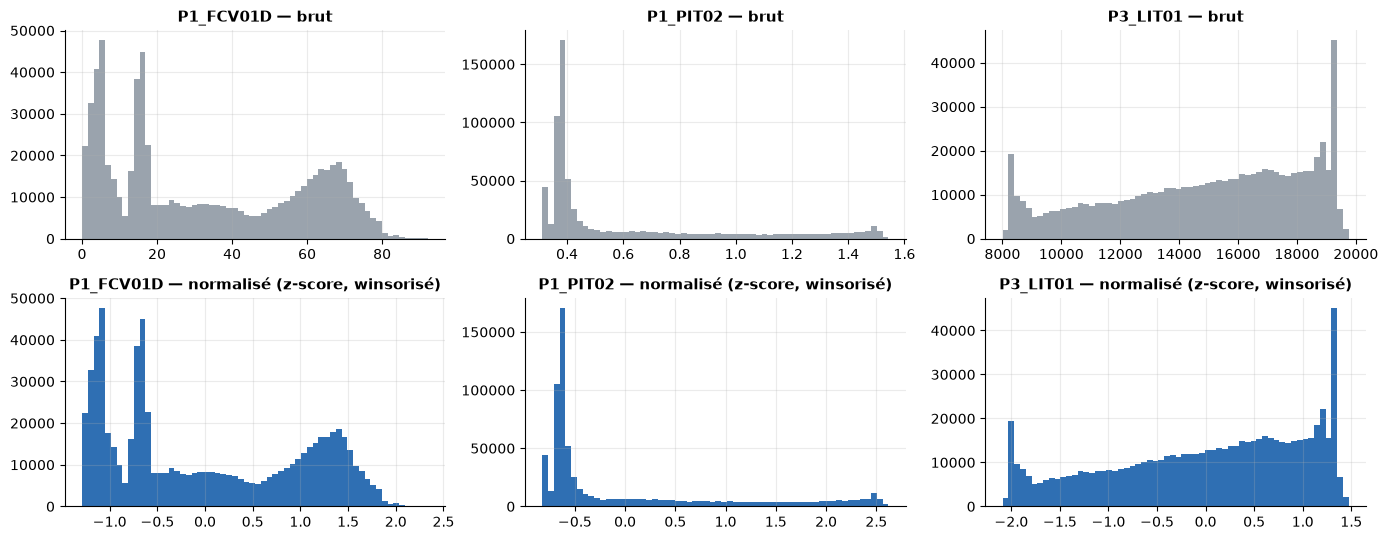

💡 [Contrôle] Après prétraitement, 9 variables ont une amplitude médiane ≥ 1,5× plus grande pendant les attaques que hors attaque sur `val` : la signature n'est pas masquée par la normalisation/winsorisation.


In [43]:
show = CONT[::max(1, len(CONT) // 3)][:3]; trn = FRAMES[PRIMARY_PROTOCOL]["train"]
fig, axes = plt.subplots(2, 3, figsize=(14, 5.5))
for j, c in enumerate(show):
    axes[0, j].hist(trn[c].dropna(), bins=60, color=PALETTE["grey"]); axes[0, j].set_title(f"{c} — brut")
    axes[1, j].hist(splits["train"][c], bins=60, color=PALETTE["train"]); axes[1, j].set_title(f"{c} — normalisé (z-score, winsorisé)")
savefig("17_avant_apres")
Zv = splits["val"][feats].abs(); lab = splits["val"]["label"].to_numpy()
ratio = (Zv[lab == 1].median() / Zv[lab == 0].median().replace(0, np.nan)).replace([np.inf, -np.inf], np.nan).dropna()
insight("Contrôle", f"Après prétraitement, {(ratio > 1.5).sum()} variables ont une amplitude médiane ≥ 1,5× plus grande pendant les attaques que hors attaque sur `val` : la signature n'est pas masquée par la normalisation/winsorisation.")

## 15. Sauvegarde et traçabilité
Un dossier **par protocole** (`data/processed/sessions/`, `data/processed/chrono/`) contenant : `train/val_normal/val/test.parquet`, `scaler.joblib`, `features.json`, `train_reference_stats.json`, `meta.json` (+ `stream_normal.parquet` pour `chrono`). Fichiers communs : `constant_rules.json`, `attack_catalog.csv`, `tag_dictionary.csv`, `reports/data_card.json`.

| Artefact | Utilité en aval |
|---|---|
| `scaler.joblib` + `features.json` | **réutilisés tels quels par l'API** (Phase 3) : même normalisation, mêmes colonnes, même ordre |
| `train_reference_stats.json` | référence du **Data Drift** (Phase 4, Evidently) |
| `stream_normal.parquet` | flux de production simulé (démo drift / réentraînement, Phases 4-5) |
| `constant_rules.json` | couche de règles (constantes à l'entraînement, bandes) : API et Decision Engine |
| `attack_catalog.csv` | évaluation par attaque (eTaPR, rappel par attaque) et validation de l'explicabilité |

In [44]:
STALE_NAMES = {"features.json", "meta.json", "train_reference_stats.json", "scaler.joblib"}
stale = [p for p in OUT_DIR.iterdir() if p.is_file() and (p.suffix == ".parquet" or p.name in STALE_NAMES)]
if stale:
    (OUT_DIR / "_obsolete").mkdir(exist_ok=True)
    for p in stale: p.replace(OUT_DIR / "_obsolete" / p.name)
    insight("Artefacts périmés", f"{len(stale)} fichier(s) d'une ANCIENNE version (racine de data/processed : {[p.name for p in stale][:6]}…) déplacés vers data/processed/_obsolete/ : ils pouvaient contenir des labels erronés (v1) ou un découpage différent. Les jeux valides sont dans data/processed/<protocole>/.")
metas = {name: save_prepared(p, OUT_DIR / name) for name, p in PROTOCOLS.items()}
tags.assign(retenue=tags.tag.isin(feats)).to_csv(OUT_DIR / "tag_dictionary.csv", index=False)
RULES = {"description": "Règles complémentaires au modèle numérique. constant_rules : alerte si valeur observée != valeur_train. band_rules : alerte si hors bande.",
         "constant_rules": RULE_TAGS,
         "evidence": {"variables_changing_only_during_attacks": att_only.index.tolist(), "attacks_touched": f"{len(touch)}/{n_att}", "median_delay_s": float(np.median(delays)) if delays else None,
                      "validated_on": "train4, test1, test2 uniquement : à confirmer sur d'autres sessions"},
         "band_rules": {n: p.band_rules for n, p in PROTOCOLS.items()}}
json.dump(RULES, open(OUT_DIR / "constant_rules.json", "w"), indent=2, default=str)
data_card = {
    "dataset": f"HAI {VERSION_TAG}", "source": "https://www.kaggle.com/datasets/icsdataset/hai-security-dataset", "environment": env,
    "files": {k: {"role": ROLE[k], "sha256": FULL_SHA.get(k)} for k in NAMES}, "label_alignment": LABEL_INFO,
    "official_catalog": {k: {"header": HEAD[k], "crosscheck_ok": f"{int(CAT[k][1]['ok'].sum())}/{len(CAT[k][1])}"} for k in HEAD},
    "parameters": {"FREQ_S": FREQ_S, "MAX_FFILL_S": MAX_FFILL_S, "TRAIN_CLIP_SIGMA": TRAIN_CLIP_SIGMA, "DROP_CORRELATED": DROP_CORRELATED, "HOLDOUT_H": HOLDOUT_H,
                   "EMBARGO_S": EMBARGO_S, "N_PLACEBO": N_PLACEBO, "UNSTABLE_Z": UNSTABLE_Z, "UNSTABLE_POLICY": UNSTABLE_POLICY, "LEVEL_Z": LEVEL_Z, "DYN_RATIO": DYN_RATIO, "SEED": SEED},
    "embargo": EMB, "protocols": metas, "attacks": {k: int(len(s)) for k, s in SEG.items()}, "integrity_gates": GATES, "constant_rules_n": len(RULE_TAGS),
    "known_limitations": [
        "Protocole « sessions » : sessions distinctes mais NON strictement chronologiques (train3/train4 postérieurs au test2) ; protocole « chrono » fourni en complément",
        "summary_label2.txt : l'en-tête annonce plus d'attaques que la liste ; les labels suivent la liste",
        "Alignement positionnel de label-test2.csv : l'ordre intra-minute est recoupé avec le catalogue officiel (seconde près), pas prouvé indépendamment",
        "Classification des tags par type : heuristique",
        "Règles sur constantes : précision élevée mais couverture limitée, validées sur 3 sessions seulement",
        "Dérive naturelle systématique entre sessions normales, d'amplitude modérée (taille d'effet à utiliser plutôt que le KS seul)",
        "Signature des attaques : seuils calibrés sur un placebo de fenêtres normales ; une attaque qui ne rompt que des relations multivariées peut échapper à cette mesure univariée",
        "Fenêtrage temporel : par colonne « session » uniquement (jamais à cheval sur deux sessions)"]}
json.dump(data_card, open(REPORT_DIR / "data_card.json", "w"), indent=2, default=str)
md_card = f"# Data card — HAI {VERSION_TAG}\n\n" + "\n".join(f"- **{n}** : {m['n_features']} variables ; " + ", ".join(f"{k} {v:,} lignes" for k, v in m["rows"].items()) for n, m in metas.items())
open(REPORT_DIR / "data_card.md", "w").write(md_card); print(md_card); print(sorted(p.name for p in OUT_DIR.iterdir()))

# Data card — HAI 23.05

- **sessions** : 66 variables ; train 697,200 lignes, val_normal 198,000 lignes, val 54,000 lignes, test 230,400 lignes
- **chrono** : 66 variables ; train 535,800 lignes, val_normal 35,400 lignes, val 54,000 lignes, test 230,400 lignes, stream 323,400 lignes
['attack_catalog.csv', 'chrono', 'constant_rules.json', 'sessions', 'tag_dictionary.csv']


**Versionnement DVC.** À exécuter **une seule fois**, dans un dépôt Git initialisé (`git init && dvc init`) :

In [45]:
# !dvc add data/raw data/processed
# !git add data/raw.dvc data/processed.dvc .gitignore reports/data_card.json
# !git commit -m "data: HAI 23.05 v1 (raw + processed sessions/chrono + data card)"
# !git tag data-v1

## 16. Synthèse, hypothèses à tester et implications pour la Phase 2

In [47]:

from collections import defaultdict
import json

by_topic = defaultdict(list)

for t, m in FINDINGS:
    by_topic[t].append(m)

for t, ms in by_topic.items():
    print(f"\n■ {t}")
    for m in ms:
        print("   •", m)

# Écriture JSON avec encodage UTF-8
json_path = REPORT_DIR / "eda_findings.json"

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(
        FINDINGS,
        f,
        indent=2,
        ensure_ascii=False
    )

print(
    f"\n{len(FINDINGS)} constats dans {json_path} ; "
    f"{len(list(FIG_DIR.glob('*.png')))} figures "
    "dans reports/figures/"
)



■ Intégrité
   • Durées cohérentes (±10 %) avec la documentation officielle HAI 23.05 : fichiers complets.

■ Schéma
   • Nombre de capteurs par fichier : [86] (attendu 86 pour HAI 23.05) — schéma homogène ✔

■ Fuite
   • Aucun chevauchement temporel entre fichiers ✔

■ Chronologie
   • Protocole « sessions » : ['train3', 'train4'] sont POSTÉRIEURS au test final (test2) ; test1 se situe entre ['train1'] et ['train2', 'train3', 'train4']. Ce n'est donc PAS un découpage chronologique strict : il mesure la généralisation entre sessions, pas une mise en production.
   • Protocole « chrono » : train = train1 + train2 (sans ses dernières heures), val_normal = ces heures, val = test1, test = test2 ; train3 + train4 (postérieurs) = flux de production simulé.
   • Fichiers contigus dans le temps (écart ≤ 5 s) : [('test1', 'train2', 1.0), ('test2', 'train3', 1.0)]. L'état du procédé se prolonge d'un fichier à l'autre : à garder en tête pour la frontière entre jeux.

■ Variables
   • 86 variable

### 16.1 Ce que le dataset impose

| Constat | Implication pour la Phase 2 | Fonction |
|---|---|---|
| Train 100 % normal, labels seulement en test (§1, §9) | apprentissage non supervisé ; seuil sur données de validation ; évaluation sur test | F5, F6 |
| Fort déséquilibre ; quelques longues attaques dominent les secondes d'attaque (§9) | métriques **par événement** (eTaPR), rappel **par attaque**, délai de détection ; jamais d'accuracy | F11 |
| Signaux très persistants (§7.3) ; attaques ≥ ~1 min | features de variation ; fenêtres 10/30/60 s **et** une fenêtre plus longue | F3, F4 |
| Dépendances locales entre variables ; dimension intrinsèque moyenne (§8) | Autoencoder ; goulot latent d'après la PCA ; explicabilité attendue sur ces paires | F5, F8, F9 |
| Sessions normales très différentes entre elles (§10) | un drift seul ne déclenche pas de réentraînement ; seuils calibrés sur cette ligne de base | F18-F21 |
| Constantes qui bougent seulement en attaque (§11.2) | couche de règles **complémentaire** (haute précision, faible couverture) | F17 |
| Deux protocoles produits (§4.3) | mesurer l'écart sessions ↔ chrono | F11, F22 |

### 16.2 Registre d'hypothèses (à trancher par expérience en Phase 2, pas par opinion)
| # | Hypothèse | Expérience |
|---|---|---|
| H1 | La performance « sessions » surestime la performance en production | comparer sessions vs chrono (mêmes modèles) |
| H2 | La winsorisation du train à ±10σ n'altère pas la détection | ablation : aucune / ±10σ / ±20σ ; vérifier la cohérence avec l'inférence |
| H3 | StandardScaler suffit malgré des distributions asymétriques | comparer à un scaler robuste (médiane/IQR) |
| H4 | Les variables quasi constantes à événements rares (P1_PCV02D, P4_HT_FD…) dégradent le modèle | garder / indicateur d'événement (≠ valeur de repos) / exclure |
| H5 | Les fenêtres 10/30/60 s suffisent | ajouter 120 s et 300 s avec pas |
| H6 | Le seuil réglé sur `val` (test1, 14 attaques, session atypique ?) se transfère au test | seuil par quantile sur `val_normal` vs sur `val` vs validation croisée par attaque |
| H7 | Garder les variables redondantes aide l'Autoencoder | `DROP_CORRELATED` True/False |
| H8 | La couche de règles améliore rappel/précision au-delà du modèle | modèle seul vs modèle + règles |
| H9 | La purge de 10 min aux frontières contiguës suffit à éviter la fuite entre sessions | avec / sans purge ; fenêtrage strictement intra-session |

### 16.3 Limites à garder en tête
- Le découpage « sessions » **n'est pas chronologique** (§4.3) ; le découpage « chrono » compense mais réduit les données.
- `summary_label2.txt` est incohérent en interne (en-tête vs liste) ; les labels suivent la liste.
- Variables « affectées » : mesure par écart local ; une attaque qui ne rompt que des **relations** entre variables peut être sous-estimée ici.
- Classification des tags par type : heuristique.

### 16.4 Étape suivante — Notebook 2 : features temporelles et fenêtres (F3, F4)
Entrées : `data/processed/<protocole>/*.parquet`, `features.json`, `constant_rules.json`. Travail : features statistiques et de variation, fenêtrage **par colonne `session`** (jamais à cheval sur deux fichiers), tests de non-fuite, puis Isolation Forest suivi dans MLflow, sur **les deux protocoles**.